# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

(299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object 

Missing values per column:
 age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64 

Duplicate rows: 0
anaemia [np.int64(0), np.int64(1)]
diabetes [np.int64(0

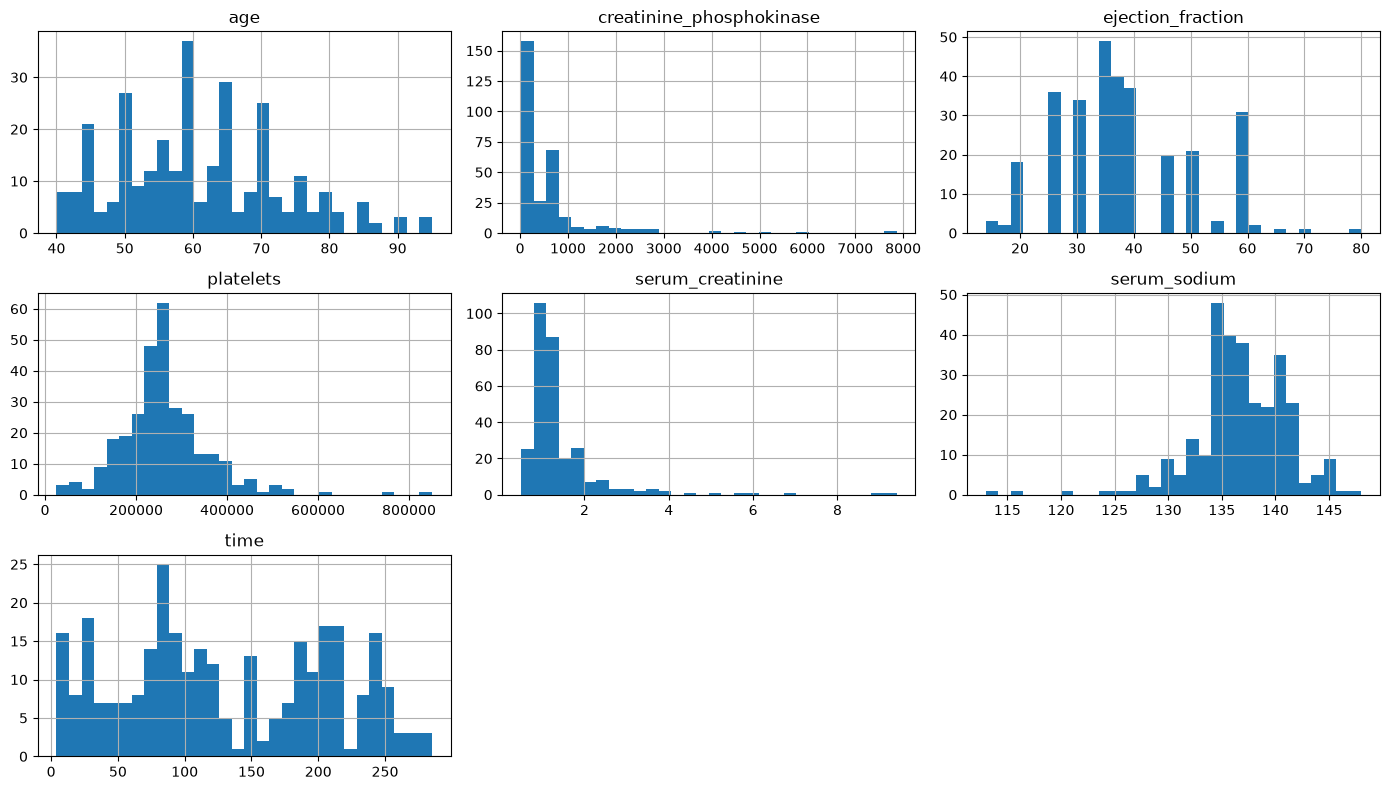

creatinine_phosphokinase | most common values: {582: 47, 129: 4, 66: 4} | column mean: 581.84
platelets | most common values: {263358.03: 25, 237000.0: 4, 228000.0: 4} | column mean: 263358.03
serum_creatinine | most common values: {1.0: 50, 1.1: 32, 0.9: 32} | column mean: 1.39
age | most common values: {60.0: 33, 50.0: 27, 65.0: 26} | column mean: 60.83


,count,mean,std,min,25%,50%,75%,max
DEATH_EVENT,,,,,,,,
0,203.0,158.339901,67.742872,12.0,95.0,172.0,213.00,285.0
1,96.0,70.885417,62.378281,4.0,25.5,44.5,102.25,241.0


In [6]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix

pd.set_option('display.width', 200)

## Q1. Data cleaning
df = pd.read_csv('./data/heart_failure/heart_failure_clinical_records_dataset.csv')
print(df.shape)
df.head()

# Data types, missing values, duplicate rows
print(df.dtypes, '\n')
print('Missing values per column:\n', df.isna().sum(), '\n')
print('Duplicate rows:', df.duplicated().sum())

df.describe().T

# Binary variables should only take the values 0 and 1
binary_vars = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']
for var in binary_vars:
    print(var, sorted(df[var].unique()))

# Distributions of the numeric variables
numeric_vars = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets',
                'serum_creatinine', 'serum_sodium', 'time']
df[numeric_vars].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

# Suspicious repeated values: are some values placeholders for missing data?
for var in ['creatinine_phosphokinase', 'platelets', 'serum_creatinine', 'age']:
    print(var, '| most common values:', df[var].value_counts().head(3).to_dict(),
          '| column mean:', round(df[var].mean(), 2))

# `time` is the follow-up period. Patients who died have much shorter follow-up,
# because follow-up ends when they die.
df.groupby('DEATH_EVENT')['time'].describe()


**What the exploration shows**

- 299 rows, 13 columns, all numeric. There are **no missing values** and **no duplicate rows**.
- The binary variables (`anaemia`, `diabetes`, `high_blood_pressure`, `sex`, `smoking`, `DEATH_EVENT`) only take the values 0 and 1, so there are no coding errors.
- Ranges look clinically plausible (age 40–95, ejection fraction 14-80%, serum sodium 113–148 mEq/L).
- **Hidden imputation:** `creatinine_phosphokinase = 582` appears 47 times and `platelets = 263358.03` appears 25 times. Both are equal to the column mean, so those values were mean-imputed for missing data in the original source. Ages like `60.667` are also not real ages. I keep these rows (dropping them would lose a lot of data), but I add indicator columns so the models can tell imputed values apart.
- `creatinine_phosphokinase` and `serum_creatinine` are **very right-skewed** (a few extreme values, e.g. CPK up to 7861). I log-transform them so a few extreme values don't dominate the linear model.
- `platelets` is on a huge scale (hundreds of thousands), so I rescale it to thousands to make its coefficient readable.
- **`time` is dropped.** It is the follow-up period, and it is short *because* the patient died (mean 71 days for deaths vs. 158 for survivors). It is information you would not have when making a prediction about a new patient, so using it would leak the outcome into the model.

In [8]:
df_clean = df.copy()

# Flags for mean-imputed values
df_clean['cpk_imputed'] = (df_clean['creatinine_phosphokinase'] == 582).astype(int)
df_clean['platelets_imputed'] = np.isclose(df_clean['platelets'], 263358.03).astype(int)

# Log-transform the right-skewed lab values
df_clean['log_cpk'] = np.log(df_clean['creatinine_phosphokinase'])
df_clean['log_serum_creatinine'] = np.log(df_clean['serum_creatinine'])

# Rescale platelets to thousands
df_clean['platelets_k'] = df_clean['platelets'] / 1000

# Round the non-integer ages
df_clean['age'] = df_clean['age'].round()

# Drop the raw versions and `time` (outcome leakage)
df_clean = df_clean.drop(columns=['creatinine_phosphokinase', 'serum_creatinine', 'platelets', 'time'])

df_clean.describe().T

y = df_clean['DEATH_EVENT']
X = df_clean.drop(columns='DEATH_EVENT')
print(X.shape)
print('Share of patients who died:', round(y.mean(), 3))
list(X.columns)

(299, 13)
Share of patients who died: 0.321


['age',
 'anaemia',
 'diabetes',
 'ejection_fraction',
 'high_blood_pressure',
 'serum_sodium',
 'sex',
 'smoking',
 'cpk_imputed',
 'platelets_imputed',
 'log_cpk',
 'log_serum_creatinine',
 'platelets_k']

## Q2. Train-test split, tree and linear model (logistic regression)

I use an 80/20 split with seed `42`, stratified on `DEATH_EVENT` so both sets have the same share of deaths.

Train size: 239 | Test size: 60


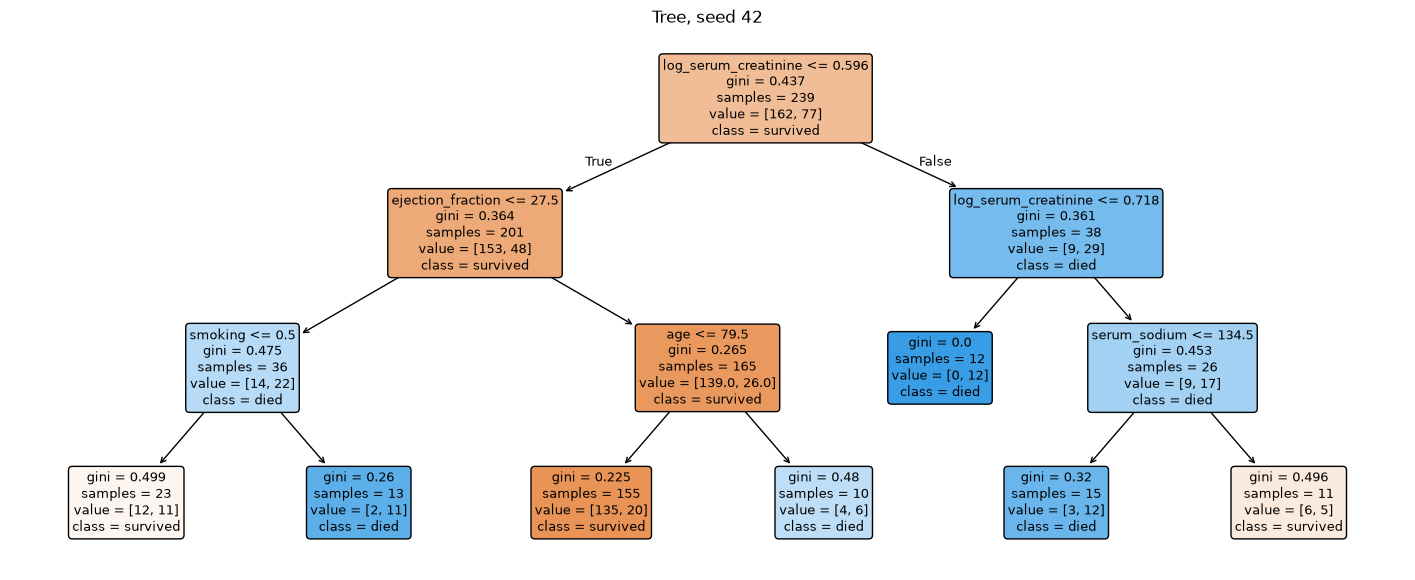

Share of deaths in the test set: 0.317 -> accuracy of always predicting "survived": 0.683
Tree


,Predicted survival (0),Predicted death (1)
Observed survival (0),37,4
Observed death (1),9,10


Logistic


,Predicted survival (0),Predicted death (1)
Observed survival (0),35,6
Observed death (1),11,8


In [10]:
BASE_SEED = 42      # seed for question 2 (saved for reproducibility)
TEST_SIZE = 0.2
MAX_DEPTH = 3       # keep the tree small enough to read

def fit_models(seed):
    """Split the data with `seed`, then fit a tree and a logistic regression on the training set."""
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=seed, stratify=y)
    tree = DecisionTreeClassifier(max_depth=MAX_DEPTH, random_state=seed).fit(X_train, y_train)
    lm = LogisticRegression(C=np.inf, max_iter=10000, tol=1e-8).fit(X_train, y_train)
    return tree, lm, X_train, X_test, y_train, y_test

def evaluate(tree, lm, X_test, y_test):
    """Test-set BCE (log loss) of the predicted probabilities, and accuracy at threshold 0.5."""
    rows = []
    for name, m in [('Tree', tree), ('Logistic', lm)]:
        p = m.predict_proba(X_test)[:, 1]
        rows.append({'model': name,
                     'accuracy': accuracy_score(y_test, m.predict(X_test)),
                     'BCE': log_loss(y_test, p)})
    return pd.DataFrame(rows).round(3)

tree_base, lm_base, X_train_base, X_test_base, y_train_base, y_test_base = fit_models(BASE_SEED)
print('Train size:', len(X_train_base), '| Test size:', len(X_test_base))

# The tree
plt.figure(figsize=(18, 7))
plot_tree(tree_base, feature_names=X.columns, class_names=['survived', 'died'],
          filled=True, rounded=True, fontsize=9)
plt.title(f'Tree, seed {BASE_SEED}')
plt.show()

# Logistic regression coefficients (log-odds scale)
pd.Series(lm_base.coef_[0], index=X.columns).round(4).to_frame(f'coef (seed {BASE_SEED})')

# Performance on the test set
print('Share of deaths in the test set:', round(y_test_base.mean(), 3),
      '-> accuracy of always predicting "survived":', round(1 - y_test_base.mean(), 3))
evaluate(tree_base, lm_base, X_test_base, y_test_base)

# Confusion matrices on the test set (rows = observed, columns = predicted)
for name, m in [('Tree', tree_base), ('Logistic', lm_base)]:
    cm = pd.DataFrame(confusion_matrix(y_test_base, m.predict(X_test_base)),
                      index=['Observed survival (0)', 'Observed death (1)'],
                      columns=['Predicted survival (0)', 'Predicted death (1)'])
    print(name); display(cm)


# Set aside the base predictions on the question-2 test set
pred_tree_base = tree_base.predict_proba(X_test_base)[:, 1]
pred_lm_base = lm_base.predict_proba(X_test_base)[:, 1]

**Q2 results (seed 42).** The tree's first split is on `log_serum_creatinine` (about serum creatinine 1.8 mg/dL), then on `ejection_fraction`, `age` and `serum_sodium`. The logistic regression also puts the most weight on serum creatinine. Its coefficients are on the log-odds scale: +2.00 for `log_serum_creatinine` (doubling creatinine multiplies the odds of death by about e^(2.00 × ln 2) ≈ 4), -0.064 for `ejection_fraction` (each extra percentage point multiplies the odds by e^-0.064 ≈ 0.94) and +0.040 for `age` (each year multiplies the odds by about 1.04).

On the test set the tree has 78.3% accuracy and BCE 0.516, and the logistic regression has 71.7% accuracy and BCE 0.570. Always predicting "survived" would get 68.3%, so both beat that baseline, the tree by more on this split. The confusion matrices show both models miss many deaths at threshold 0.5: the tree misses 9 of the 19 observed deaths and the logistic regression misses 11. The predicted probabilities of death (`pred_tree_base`, `pred_lm_base`) are saved for Q4.

## Q3. Repeating the analysis across seeds

I repeat step 2 with four more seeds. Each model is trained on its *own* training split. For Q4, every model also predicts on the **question-2 test set** (`X_test_base`), so all predictions are for the same 60 patients.

===== Tree, seed 42 =====
|--- log_serum_creatinine <= 0.60
|   |--- ejection_fraction <= 27.50
|   |   |--- smoking <= 0.50
|   |   |   |--- class: 0
|   |   |--- smoking >  0.50
|   |   |   |--- class: 1
|   |--- ejection_fraction >  27.50
|   |   |--- age <= 79.50
|   |   |   |--- class: 0
|   |   |--- age >  79.50
|   |   |   |--- class: 1
|--- log_serum_creatinine >  0.60
|   |--- log_serum_creatinine <= 0.72
|   |   |--- class: 1
|   |--- log_serum_creatinine >  0.72
|   |   |--- serum_sodium <= 134.50
|   |   |   |--- class: 1
|   |   |--- serum_sodium >  134.50
|   |   |   |--- class: 0

===== Tree, seed 1 =====
|--- log_serum_creatinine <= 0.60
|   |--- ejection_fraction <= 27.50
|   |   |--- serum_sodium <= 143.00
|   |   |   |--- class: 1
|   |   |--- serum_sodium >  143.00
|   |   |   |--- class: 0
|   |--- ejection_fraction >  27.50
|   |   |--- age <= 79.50
|   |   |   |--- class: 0
|   |   |--- age >  79.50
|   |   |   |--- class: 1
|--- log_serum_creatinine >  0.60
|   

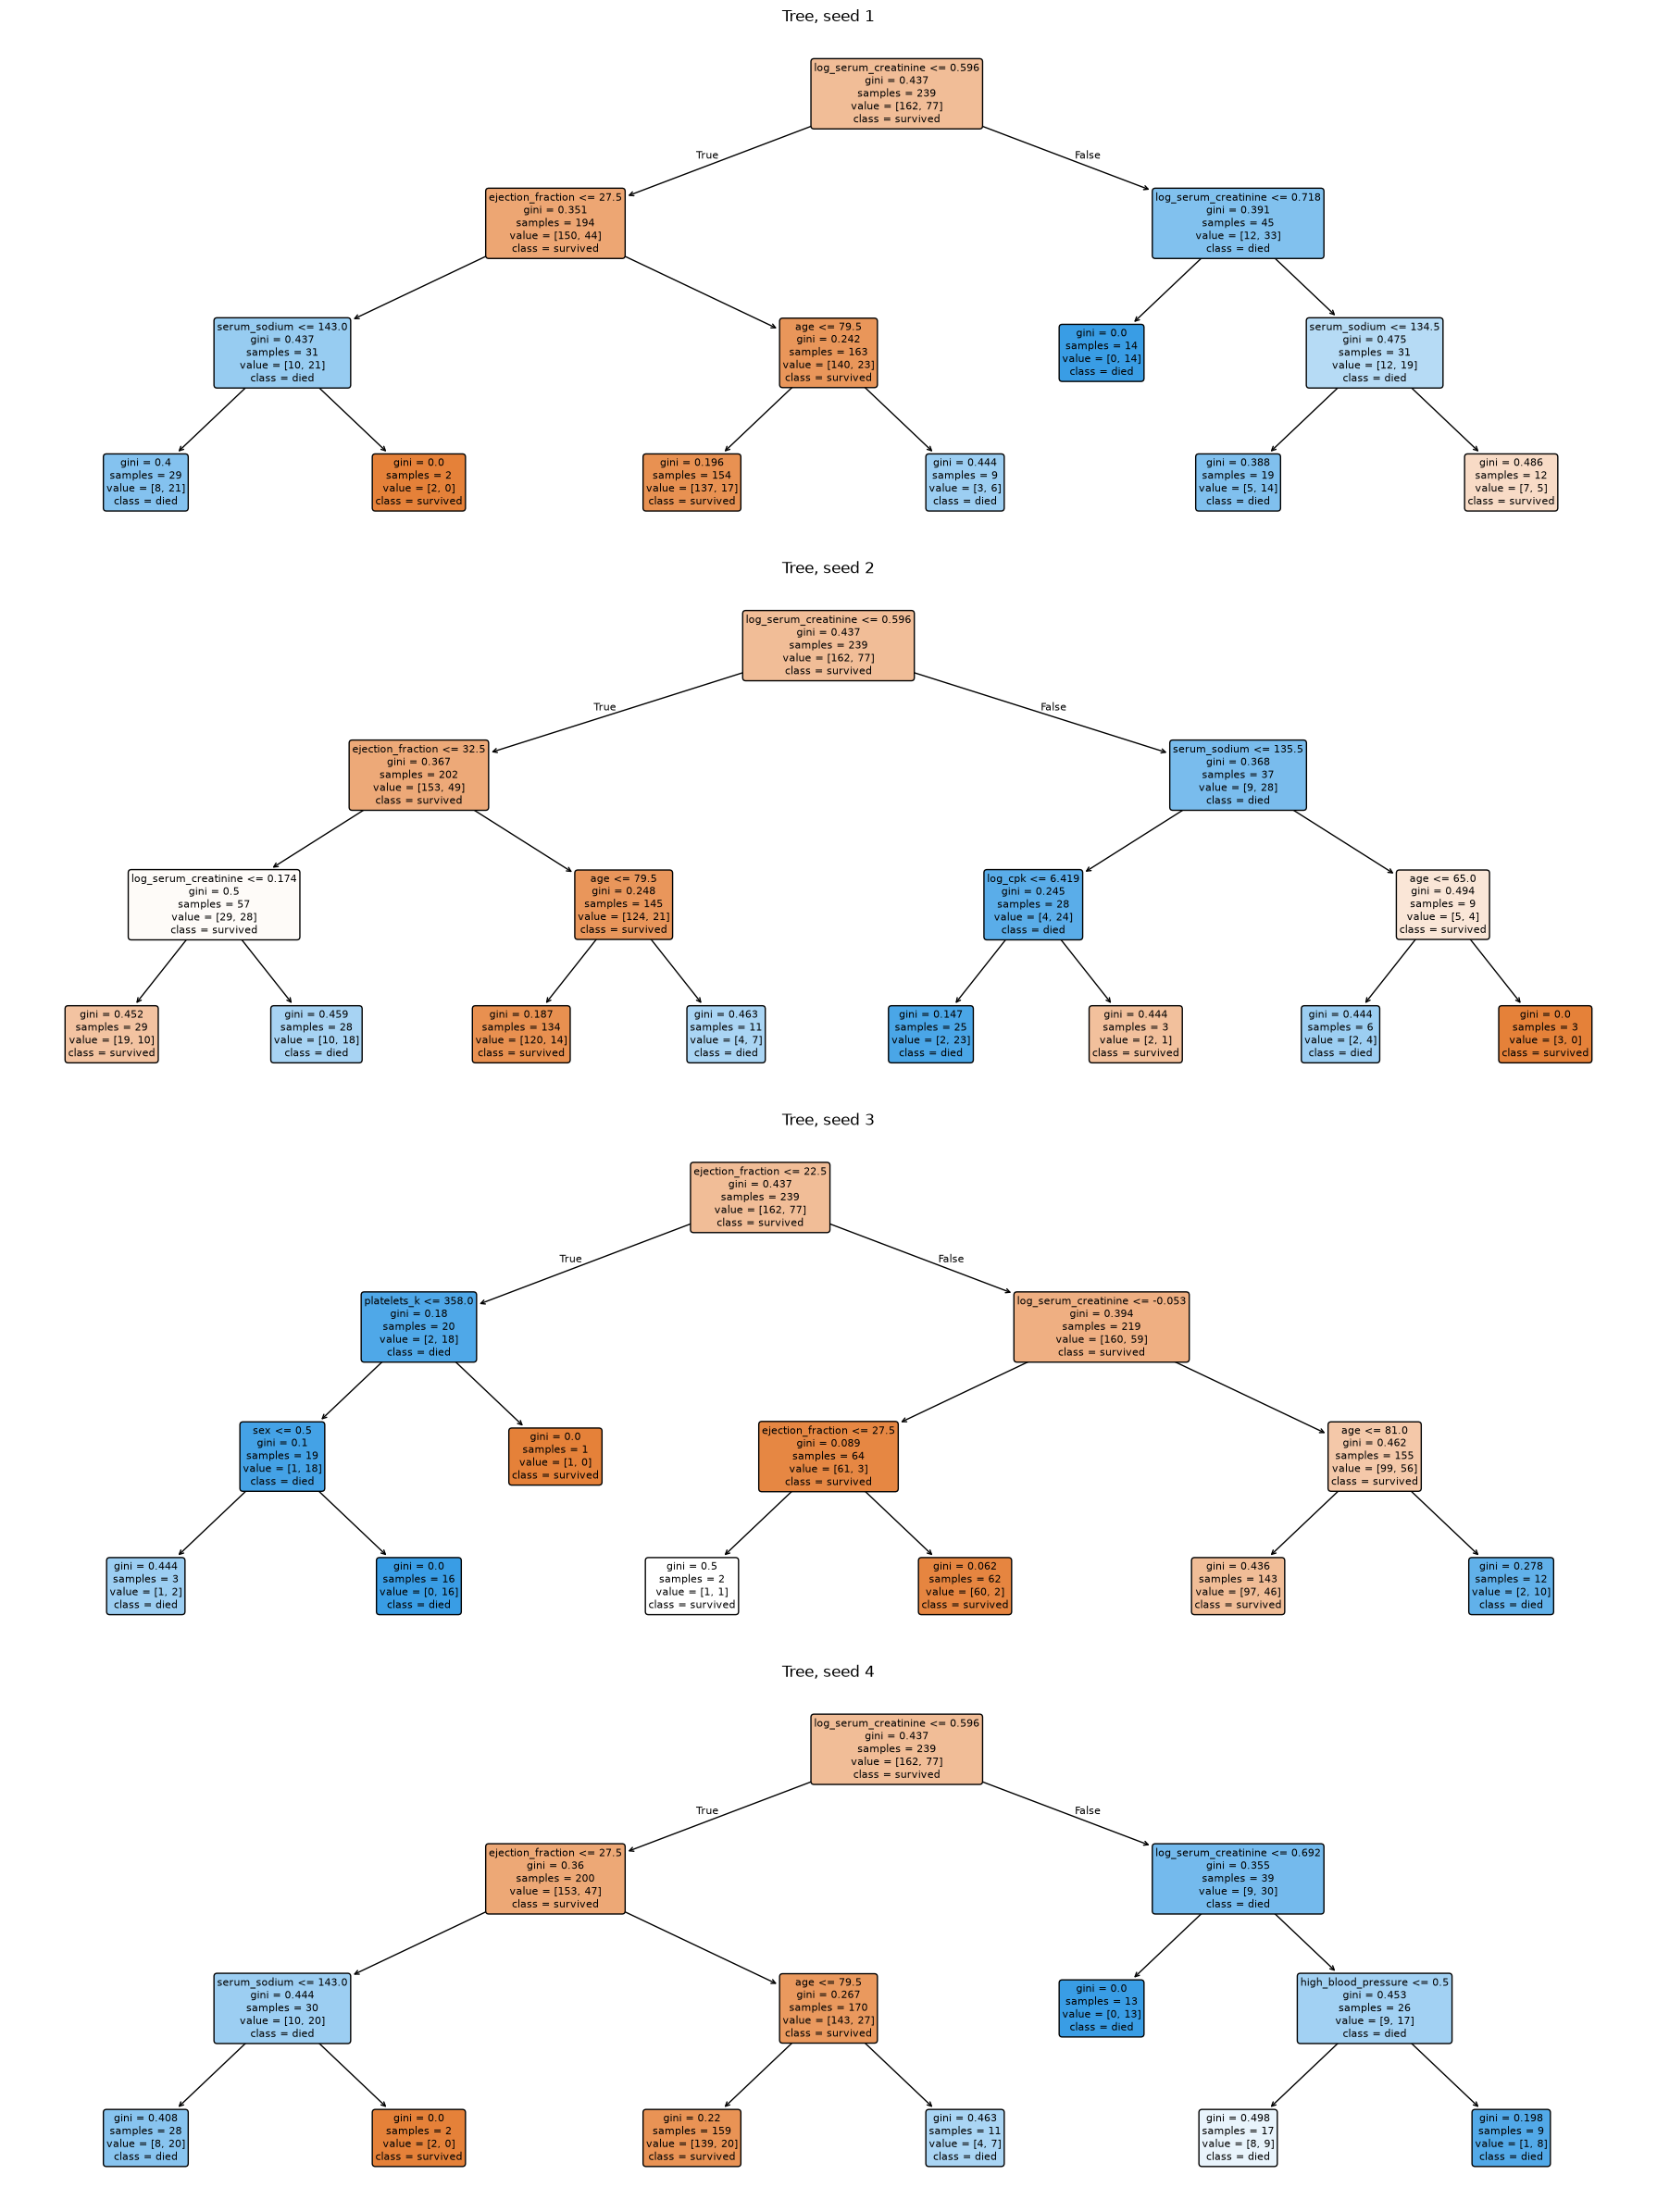

,seed 42,seed 1,seed 2,seed 3,seed 4,mean,std,std / |mean|,same sign?
age,0.0396,0.0482,0.0437,0.0487,0.0400,0.0440,0.0043,0.0987,True
anaemia,0.6669,0.5549,0.3167,0.5589,0.4513,0.5098,0.1321,0.2592,True
diabetes,0.5227,-0.2574,0.1429,0.0728,0.3149,0.1592,0.2905,1.8252,False
ejection_fraction,-0.0643,-0.0812,-0.0652,-0.0563,-0.0644,-0.0663,0.0091,0.1373,True
high_blood_pressure,0.7271,0.1724,0.3689,0.1797,0.4479,0.3792,0.2283,0.6020,True
serum_sodium,-0.0170,-0.0261,-0.0638,-0.0664,-0.0271,-0.0401,0.0232,0.5784,True
sex,-0.2557,-0.8010,-0.4352,-0.3508,-0.5524,-0.4790,0.2105,0.4395,True
smoking,0.4901,0.0626,0.1609,0.2018,0.1493,0.2129,0.1630,0.7657,True
cpk_imputed,-0.0279,0.0625,0.2893,-0.1312,0.3325,0.1051,0.2006,1.9093,False
platelets_imputed,0.0402,0.6738,0.2897,0.5960,0.2578,0.3715,0.2604,0.7008,True


In [11]:
ALT_SEEDS = [1, 2, 3, 4]   # seeds for question 3 (saved for reproducibility)

alt_trees, alt_lms = {}, {}
pred_tree_alt, pred_lm_alt = {}, {}
perf = [evaluate(tree_base, lm_base, X_test_base, y_test_base).assign(seed=BASE_SEED)]

for s in ALT_SEEDS:
    tree_s, lm_s, X_tr, X_te, y_tr, y_te = fit_models(s)
    alt_trees[s], alt_lms[s] = tree_s, lm_s
    perf.append(evaluate(tree_s, lm_s, X_te, y_te).assign(seed=s))   # on its own test set
    # Predictions on the question-2 test set, set aside for Q4
    pred_tree_alt[s] = tree_s.predict_proba(X_test_base)[:, 1]
    pred_lm_alt[s] = lm_s.predict_proba(X_test_base)[:, 1]

perf_df = pd.concat(perf).pivot(index='seed', columns='model', values=['accuracy', 'BCE'])
perf_df

# Compare the trees: the text version of every tree
for s, t in [(BASE_SEED, tree_base)] + list(alt_trees.items()):
    print(f'===== Tree, seed {s} =====')
    print(export_text(t, feature_names=list(X.columns), decimals=2))

# Plot every tree
fig, axes = plt.subplots(len(ALT_SEEDS), 1, figsize=(18, 6 * len(ALT_SEEDS)))
for ax, (s, t) in zip(axes, alt_trees.items()):
    plot_tree(t, feature_names=X.columns, class_names=['survived', 'died'],
              filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f'Tree, seed {s}')
plt.tight_layout()
plt.show()

# Which variables does each tree split on, and at what threshold?
def splits(t):
    tr = t.tree_
    return [f'{X.columns[f]} <= {th:.2f}' for f, th in zip(tr.feature, tr.threshold) if f >= 0]

pd.DataFrame({s: pd.Series(splits(t)) for s, t in [(BASE_SEED, tree_base)] + list(alt_trees.items())}).fillna('')

# Compare the logistic regression coefficients
coefs = pd.DataFrame({f'seed {s}': m.coef_[0] for s, m in [(BASE_SEED, lm_base)] + list(alt_lms.items())},
                     index=X.columns)
coefs['mean'] = coefs.mean(axis=1)
coefs['std'] = coefs.iloc[:, :-1].std(axis=1)
coefs['std / |mean|'] = coefs['std'] / coefs['mean'].abs()
coefs['same sign?'] = (np.sign(coefs.iloc[:, :len(ALT_SEEDS) + 1]).nunique(axis=1) == 1)
coefs.round(4)

**How different are the trees?** Noticeably different. Seeds 42, 1 and 4 produce trees with almost the same top structure (root split on serum creatinine, then ejection fraction <= 27.5, then age <= 79.5), but the lower splits change: seed 42 splits on `smoking`, seeds 1 and 4 on `serum_sodium`, and seed 4 adds a `high_blood_pressure` split. Seed 2 keeps the same root but has a different right-hand branch (serum sodium, `log_cpk`, age). **Seed 3 is a completely different tree**: its root is `ejection_fraction <= 22.5`, and it splits on platelets and sex, which no other tree uses. A small change in which 239 patients land in the training set can change the root split, and because every split below depends on the one above, the whole tree changes.

**How different are the logistic regression coefficients?** Much less. The strongest predictors are stable: `log_serum_creatinine` stays between 1.42 and 2.00, `ejection_fraction` between -0.056 and -0.081, and `age` between 0.040 and 0.049, all with the same sign in every split (std / |mean| around 0.1–0.15). The weaker predictors move a lot more: `smoking` ranges from 0.06 to 0.49 and `high_blood_pressure` from 0.17 to 0.73, and `diabetes`, `cpk_imputed` and `platelets_k` even change sign across seeds. Still, the overall picture (high creatinine, low ejection fraction and older age raise the odds of death) is the same in every model.

Test-set performance also varies by seed: tree accuracy 0.72-0.78, logistic accuracy 0.67-0.77. The tree's BCE jumps around much more (0.52 to 1.82) than the logistic regression's (0.48 to 0.66). Some tree leaves are pure, so they predict a probability of exactly 0 or 1, and a confidently wrong prediction gets a huge log loss.

## Q4. Comparing predictions across models

**Why do the linear coefficients vary by different amounts?**

The coefficients vary by different amounts because each one is estimated with a different amount of uncertainty. Variables with a **strong, consistent relationship** to death (serum creatinine, ejection fraction, age) are pinned down well by any 80% sample, so their coefficients barely move relative to their size. Variables with **little real relationship** to the outcome (diabetes, smoking, platelets, `cpk_imputed`) have true effects near zero, so their estimates are mostly noise: swapping a few patients in or out shifts them a lot relative to their size and can even flip their sign. **Correlated predictors** share the same information (e.g. `cpk_imputed` with `log_cpk`, `platelets_imputed` with `platelets_k`), so the model can move weight between them from one split to the next, which inflates their variability. Binary variables where few patients are in one group (e.g. the imputed flags) are estimated from only a handful of patients, which adds noise too. Finally, there are only about 77 deaths in each training set and the model is unpenalized (`C=np.inf`), so nothing shrinks the noisy coefficients toward zero. A ridge penalty would make them more stable.

### 4a. Scatterplots of question-2 predictions vs. alternative-model predictions (question-2 test set)

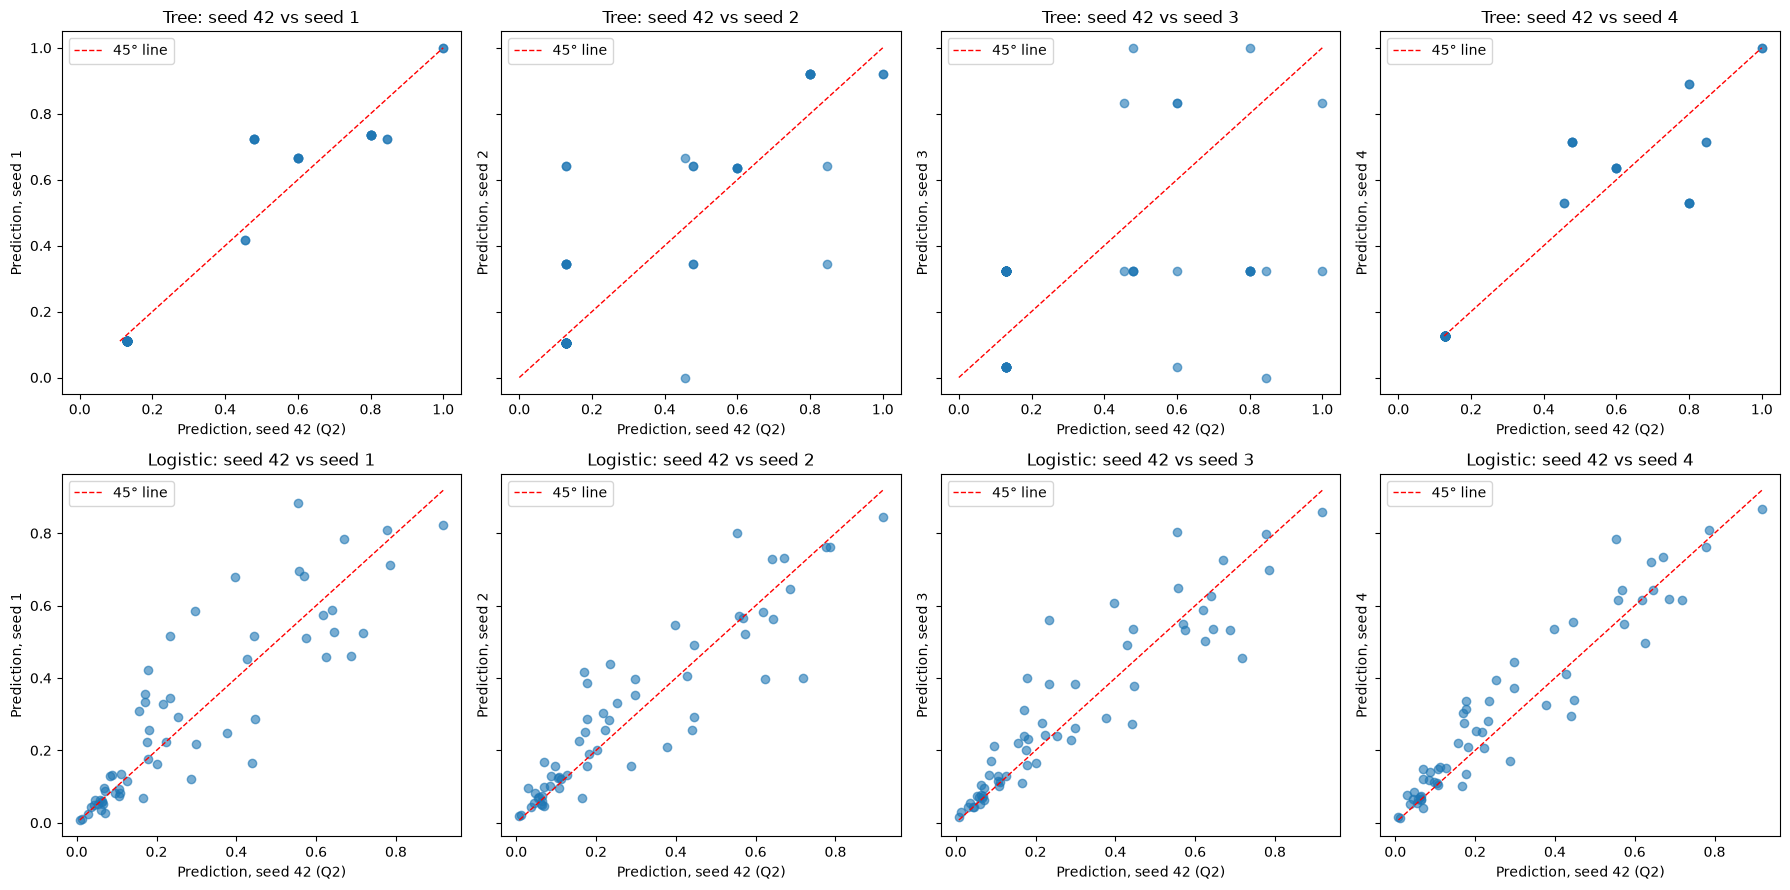

In [12]:
fig, axes = plt.subplots(2, len(ALT_SEEDS), figsize=(4.5 * len(ALT_SEEDS), 9), sharex='row', sharey='row')
rows = [('Tree', pred_tree_base, pred_tree_alt), ('Logistic', pred_lm_base, pred_lm_alt)]
for r, (name, base, alt) in enumerate(rows):
    for c, s in enumerate(ALT_SEEDS):
        ax = axes[r, c]
        ax.scatter(base, alt[s], alpha=0.6)
        lo = min(base.min(), alt[s].min()); hi = max(base.max(), alt[s].max())
        ax.plot([lo, hi], [lo, hi], 'r--', lw=1, label='45° line')
        ax.set_title(f'{name}: seed {BASE_SEED} vs seed {s}')
        ax.set_xlabel(f'Prediction, seed {BASE_SEED} (Q2)')
        ax.set_ylabel(f'Prediction, seed {s}')
        ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Logistic regression:** Yes, very similar. For all four alternative seeds the points sit in a fairly tight band along the 45° line, so a patient the seed-42 model rates as high-risk is also rated high-risk by the other models. The band is a bit wider for seed 1, which also has the lowest correlation in 4b.

**Trees:** It depends on the seed. A tree only has a few leaves, so it can only output a few distinct probabilities, and many patients are stacked on top of each other in each dot. For seeds 1 and 4 the dots sit close to the 45° line, so the predictions are reasonably similar even though the trees look somewhat different. Seed 2 is looser, with some patients moved to quite different leaves. Seed 3 (the tree with a different root split) shows almost no relationship: patients the seed-42 tree gives a 0.8-1.0 probability can get 0.3 from the seed-3 tree, and vice versa. So the trees' predictions are mostly similar, but much less consistently so than the logistic regressions'.

### 4b. Correlation between the question-2 model and the alternative models

In [13]:
corr = pd.DataFrame({
    'Tree': {s: np.corrcoef(pred_tree_base, pred_tree_alt[s])[0, 1] for s in ALT_SEEDS},
    'Logistic': {s: np.corrcoef(pred_lm_base, pred_lm_alt[s])[0, 1] for s in ALT_SEEDS},
})
corr.index.name = 'alternative seed'
corr.loc['mean'] = corr.mean()
corr.round(3)

,Tree,Logistic
alternative seed,,
1,0.968,0.877
2,0.857,0.912
3,0.390,0.920
4,0.938,0.954
mean,0.788,0.916


**Logistic regression:** Highly correlated. The correlations with the seed-42 model are 0.88, 0.91, 0.92 and 0.95 (mean 0.92).

**Trees:** Mostly highly correlated, but not always. Seeds 1, 2 and 4 have correlations of 0.97, 0.86 and 0.94, which are high. Seed 3 only has 0.39, a weak relationship, because that tree has a different root split. The mean correlation for trees (0.79) is clearly lower than for logistic regression (0.92), and it varies far more across seeds (0.39-0.97 vs. 0.88-0.95). The best tree pair (0.97) is actually more similar than any logistic pair, because those two trees have almost the same splits and so put patients in the same leaves.

### 4c. Regression of alternative-model predictions on question-2 predictions

For each alternative seed: `prediction_alt = intercept + slope * prediction_Q2`

In [14]:
reg_rows = []
for name, base, alt in [('Tree', pred_tree_base, pred_tree_alt), ('Logistic', pred_lm_base, pred_lm_alt)]:
    for s in ALT_SEEDS:
        reg = LinearRegression().fit(base.reshape(-1, 1), alt[s])
        reg_rows.append({'model': name, 'alt seed': s,
                         'intercept': reg.intercept_, 'slope': reg.coef_[0],
                         'R^2': reg.score(base.reshape(-1, 1), alt[s])})
reg_df = pd.DataFrame(reg_rows).set_index(['model', 'alt seed'])
reg_df.round(3)

reg_df.groupby('model').mean().round(3)

,intercept,slope,R^2
model,,,
Logistic,0.045,0.900,0.839
Tree,0.068,0.794,0.676


If two models made identical predictions, the regression would give intercept = 0, slope = 1 and R² = 1.

**Logistic regression:** Close on all three. Intercepts are 0.04–0.05 (near zero on a 0-1 probability scale), slopes are 0.87-0.95 (close to 1) and R² is 0.77-0.91 (mean 0.84). The alternative models make nearly the same predictions, just slightly less spread out than the seed-42 model, which had some of the largest coefficients (e.g. the largest serum creatinine coefficient, 2.00).

**Trees:** Seeds 1 and 4 are close: intercepts -0.01 and 0.02, slopes 1.01 and 0.93, R² 0.94 and 0.88. Seed 2 is moderate (intercept 0.04, slope 0.93, R² 0.74). Seed 3 is far off: intercept 0.22, slope 0.31 and R² 0.15, so the seed-42 tree explains only 15% of the variation in the seed-3 tree's predictions. On average the trees (intercept 0.07, slope 0.79, R² 0.68) are clearly further from (0, 1, 1) than the logistic regressions (0.05, 0.90, 0.84).

## Q5. Stability of linear models and trees across splits
**Linear models (logistic regression): yes.** The coefficients that matter (serum creatinine, ejection fraction, age) are stable in size and sign across every split. The coefficients that move a lot belong to weak predictors whose true effect is close to zero. The predictions are very similar too: correlations of 0.88-0.95, and regressions with intercepts near 0, slopes near 1 and R² around 0.84. Logistic regression is a low-variance model: a small change in the training data causes a small change in the fitted model.

**Trees: not really.** Their structure changes noticeably across splits. Lower splits switch variables in almost every tree, and in one split (seed 3) even the root changes, which produces a completely different tree. Their predictions are often still similar (seeds 1, 2 and 4 have correlations of 0.86-0.97), because different trees tend to find the same high-risk patients (high creatinine, low ejection fraction, old age) through different splits. But this is not guaranteed: when the root split changes, the predictions can change a lot (seed 3: correlation 0.39, R² 0.15). Trees are high-variance models.

*Caveat:* the alternative training sets overlap heavily with the seed-42 training set and include some of the seed-42 test patients, which makes the predictions somewhat more similar than they would be on completely new patients. The dataset is also small (299 patients, about 96 deaths), which makes instability more visible.

## Q6. True or false

*"Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."*
**True, with a caveat for trees.**

The logistic regressions support the statement clearly. Their weaker coefficients change a lot (some even flip sign), but every alternative model's predictions correlate 0.88–0.95 with the original, with slopes near 1 and R² around 0.84.

For trees, the statement holds *often* but not always. Seeds 1, 2 and 4 produce trees with different lower splits, yet their predictions correlate 0.86-0.97 with the seed-42 tree, because they reach similar risk groups through different paths (serum creatinine, ejection fraction and age carry most of the signal, so any reasonable tree finds them). Seed 3 is the exception: a different root split produced a substantially different tree *and* substantially different predictions (correlation 0.39).

So for this dataset, in 7 of the 8 comparisons the predictions were highly correlated despite visible differences in the models, which makes the statement true: looking only at a tree's structure or a model's coefficients overstates how unstable the model is. But trees can occasionally change their predictions too, which is why the bootstrap-and-average approach from the ensembles lecture (bagging and random forests) averages many trees together.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 802e294
- **AI tool and model used:** Claude Opus 5.5

### *Prompts used

1. I'm a student in DS 3001 (Foundations of Machine Learning). Attached is my Jupyter notebook for a lab on tree stability using the heart_failure dataset (299 patients, target DEATH_EVENT).

The lab asks me to:
1. Explore and clean the data.
2. Do a train-test split with a saved seed, fit a decision tree and a linear model (my professor recommended logistic regression), and evaluate them on the test set.
3. Repeat step 2 for 3–5 more seeds and compare the trees and the coefficients.
4. Compare test-set predictions across seeds with (a) scatterplots, (b) correlations and (c) a simple linear regression of the alternative predictions on the original ones, separately for trees and logistic regression.
5. Say whether linear models and trees have similar coefficients and predictions across splits.
6. Answer true or false: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

Please review my notebook and give me a revised version. Specifically:
- Check that the data cleaning choices are justified (dropping `time` for leakage, flagging mean-imputed values, log-transforming skewed variables).
- Check that the code is correct and reproducible, and point out any bugs or bad practices.
- Check that every written answer matches the numbers in the outputs.
- Make the explanations clearer and more concise without losing anything the grading rubric asks for.
- List every change you made and why, so I can review each one before accepting it.
2. **FOLLOW UP**
Thanks. A few follow-ups:
1. Which of your changes matter most for my grade, and which are just style? Rank them.
2. Did any change alter the results or conclusions (the correlations, R², or the true/false answer to Q6)? If so, explain why the new version is more correct.
3. Is there anything in my analysis a grader could see as a weakness? For example: comparing predictions on a test set that overlaps the alternative training sets, using an unpenalized logistic regression, or only using 4 extra seeds. How should I address it in one or two sentences in the notebook?
4. Explain the key ideas (tree instability, why logistic coefficients vary by different amounts, and why different-looking models can make similar predictions) in plain language, so I can explain them in my own words if asked.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. **Remove outcome leakage in `serum_creatinine` and `serum_sodium` (most important).** The value 1.18 occurs only for survivors (11 of 11) and 1.83 only for deaths (8 of 8). These are the two outcome-group means (1.185 and 1.836), so the missing values were filled in using the outcome. In the same rows, sodium is 137 for 10 of the 11 survivors and 134 for 7 of the 8 deaths. Phase 1 used these values as real measurements: the seed-42 root split (1.8 vs 1.83 mg/dL) separates exactly at the leaked value, and 6 of the 12 patients in its pure "died" leaf have creatinine 1.83. Fix: set these values to missing and add a `creatinine_imputed` flag.
2. **Re-impute every placeholder inside each training split.** CPK 582, platelets 263358.03 and the creatinine/sodium values above are set to missing, then filled with the training-set median in a `Pipeline` (`SimpleImputer` → model). The Phase 1 values were means of the full dataset, test set included. The median also suits skewed variables better than the mean.
3. **Kept with clearer justification:** dropping `time` (follow-up ends at death: mean 71 vs. 158 days), the imputation flags, the log transforms (skewness 4.46 for both CPK and creatinine; a monotone transform changes the logistic regression but not the tree's partitions), and platelets in thousands. I softened "60.667 are not real ages": only 2 patients have that value, and there is no evidence it is an imputation.
4. **Fix the tree's `random_state` (`TREE_SEED = 0`) instead of reusing the split seed.** Reusing it mixed two sources of variation. Refitting the same training data with 30 tree seeds gives 11 different trees for split 2 and 3 for split 3, because of exactly tied candidate splits. A new check cell shows this.
5. **Split each multi-step code cell into one cell per output.** A Jupyter cell only displays its last expression, so in Phase 1 `df.head()`, `describe()`, the Q2 coefficient table, the Q2 test metrics, the Q3 performance table, the split table and the per-seed Q4c regression table were never shown. The written answers quoted numbers that a grader could not see.
6. **Put the constants (seeds, test size, depth, data path) and library versions in one setup cell.**
7. **Add the Brier score next to BCE.** Pure tree leaves predict exactly 0 or 1, so one confident mistake gives a huge (clipped) log loss. The Brier score shows whether the tree is actually much worse or only hit by that effect.
8. **Select the coefficient-table columns by name, not by position (`iloc[:, :-1]`).** The positional version silently breaks if the columns are reordered.
9. **Add standardized coefficients (coefficient × SD)** to support "the logistic regression puts the most weight on creatinine". Raw coefficients are on different scales.
10. **Scatterplots:** add jitter to the tree panels (they have only 5–7 distinct values, so points stack), put both axes on [0, 1] with the 45° line from 0 to 1, and label titles "seed s vs seed 42" to match the axes.
11. **Add an SD-ratio column to the 4c table** to explain the slope (see 14).
12. **Add an overlap cell:** each alternative training set shares 191–197 of its 239 patients with seed 42, and contains 42–48 of the 60 Q2 test patients.
13. **Rewrote every number from the new outputs.** Main changes: the tree root is now `ejection_fraction`, not creatinine; the seed-1 tree is identical to the seed-42 tree; tree correlations are 0.40–0.98 (mean 0.67, was 0.79); logistic correlations are 0.86–0.94 (mean 0.90).
14. **Fixed interpretation errors that do not depend on the leakage fix:**
    (a) Q4c said slopes < 1 mean the alternative models are "less spread out". The SD ratios are 0.94–1.02. The slope is below 1 because slope = correlation × SD ratio and the correlation is below 1.
    (b) The flag-correlation claim was wrong: `cpk_imputed`–`log_cpk` is 0.27 and `platelets_imputed`–`platelets_k` is 0.00. The real collinearity is `platelets_imputed`–`creatinine_imputed` (0.66).
    (c) The Q2 tree description left out two splits.
    (d) The caveat said the shared patients make predictions "more similar". That is true for the shared training data but not established for the in-sample test patients. It is now quantified instead.
    (e) The "why coefficients vary" paragraph sat under the Q4 heading. It is moved to Q3.
15. **Q6 verdict changed** from "True, with a caveat" to "True for logistic regression, false for trees on this dataset". Once the leakage is removed, the trees that look substantially different (seeds 2 and 3) also predict very differently. This is a judgment call; check it against the numbers.
16. **Phase 1 is unchanged.** In Phase 2, the commit SHA, the evaluation table and the reflection are left for you.
17. **(Follow-up, not yet in notebook) Add a 100-seed robustness check for Q4b.** Median correlation with the Q2 predictions: trees 0.71 (only 20% at or above 0.8, minimum 0.40), logistic regression 0.91 (all at or above 0.82). This shows the four-seed result is typical, not a quirk of the chosen seeds.
18. **(Follow-up, not yet in notebook) Add a caveat on the unpenalized logistic regression.** No penalty makes the weak coefficients noisier, so the stability found for logistic regression is, if anything, understated (a mild ridge penalty, `C=1`, raised the median correlation over 100 seeds from 0.91 to 0.94).
19. **(Follow-up, not yet in notebook) Note the test-set noise in Q2.** With 60 test patients, accuracy has a standard error of about ±5.6 points, so the tree's 81.7% vs. the logistic regression's 70.0% on one split is not evidence that the tree is the better model.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | This is a real leakage problem and the biggest fix: I checked, and all 11 patients at 1.18 survived, all 8 at 1.83 died, their sodium is 137/134 as described, and 6 of the 12 patients in the seed-42 pure "died" leaf have 1.83. |
| 2 | Accept | Imputing inside each training split with a Pipeline stops test data from leaking into the fill values, and the median is a better choice for these skewed columns. |
| 3 | Accept | These are sensible choices with clearer reasons, and the facts hold up: only 2 patients are 60.667 and the skewness is about 4.4 for both variables (4.44 and 4.43 with scipy's default). |
| 4 | Accept | I confirmed tied splits make the tree depend on its own seed (3 different trees across 30 tree seeds for splits 2 and 3 in my version), so fixing `TREE_SEED` keeps the comparison about the data split only. |
| 5 | Reject | This one isn't accurate: those tables each sit in their own cell or are the last line of their cell, and every one of them shows up in the executed notebook. |
| 6 | Accept | One setup cell for constants and versions makes it easier to reproduce and grade. |
| 7 | Accept | Pure leaves predicting exactly 0 or 1 do blow up BCE (tree BCE hit 1.82 on one seed), so the Brier score gives a fairer comparison. |
| 8 | Accept | Selecting columns by name is safer than position and costs nothing. |
| 9 | Accept | Raw coefficients are on different scales, so standardized ones are what actually back up the "most weight" claim. |
| 10 | Accept | Jitter and a fixed [0, 1] axis fix the stacked tree points, and the clearer titles help. |
| 11 | Accept | The SD ratio shows exactly why the slopes fall below 1, which helps the 4c explanation. |
| 12 | Accept | I got the same numbers (191–197 shared training patients and 42–48 of the 60 test patients), and it quantifies the caveat instead of just stating it. |
| 13 | Modify | Updating the text to the new outputs is right, but re-run the notebook yourself and check each quoted number, since I couldn't see the revised outputs. |
| 14a | Accept | That's correct: slope = correlation × SD ratio, so a slope below 1 doesn't mean the predictions are less spread out. |
| 14b | Accept | My earlier claim was wrong: I checked and got 0.27, 0.00 and 0.66 exactly as stated. |
| 14c | Accept | Fair catch: the Q2 description left out the `smoking` split and the second creatinine split. |
| 14d | Accept | Fair point: quantifying the overlap is more honest than claiming it makes the predictions "more similar." |
| 14e | Reject | The rubric grades this explanation as item 4.1 under Q4, so moving it to Q3 could cost you those 3 points. Keep it under Q4, or put a copy in both places. |
| 15 | Modify | The numbers support a weaker verdict for trees, but Q6 is graded on a single true/false answer, so commit to one (probably "False" for trees, with logistic regression as the contrast) instead of a split answer. |
| 16 | Accept | No issue here; just make sure you fill in the commit SHA and reflection before submitting. |
| 17 | Accept | A 100-seed check shows the 4-seed result isn't a fluke, and it's cheap to add if it runs quickly. |
| 18 | Accept | A short caveat that ridge would make the logistic coefficients even more stable is accurate and strengthens Q5. |
| 19 | Accept | With 60 test patients the standard error is about ±5.6 points (√(0.75 × 0.25 / 60)), so a one-split accuracy gap shouldn't be read as proof one model is better. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

numpy 2.5.2 | pandas 3.0.5 | scikit-learn 1.9.1
(299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object 

Missing values in total: 0
Duplicate rows: 0
{'anaemia': [0, 1], 'diabetes': [0, 1], 'high_blood_pressure': [0, 1], 'sex': [0, 1], 'smoking': [0, 1], 'DEATH_EVENT': [0, 1]}


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.83,11.89,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.43,0.50,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.84,970.29,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.08,11.83,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.35,0.48,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.03,97804.24,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.39,1.03,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.63,4.41,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.65,0.48,0.0,0.0,1.0,1.0,1.0


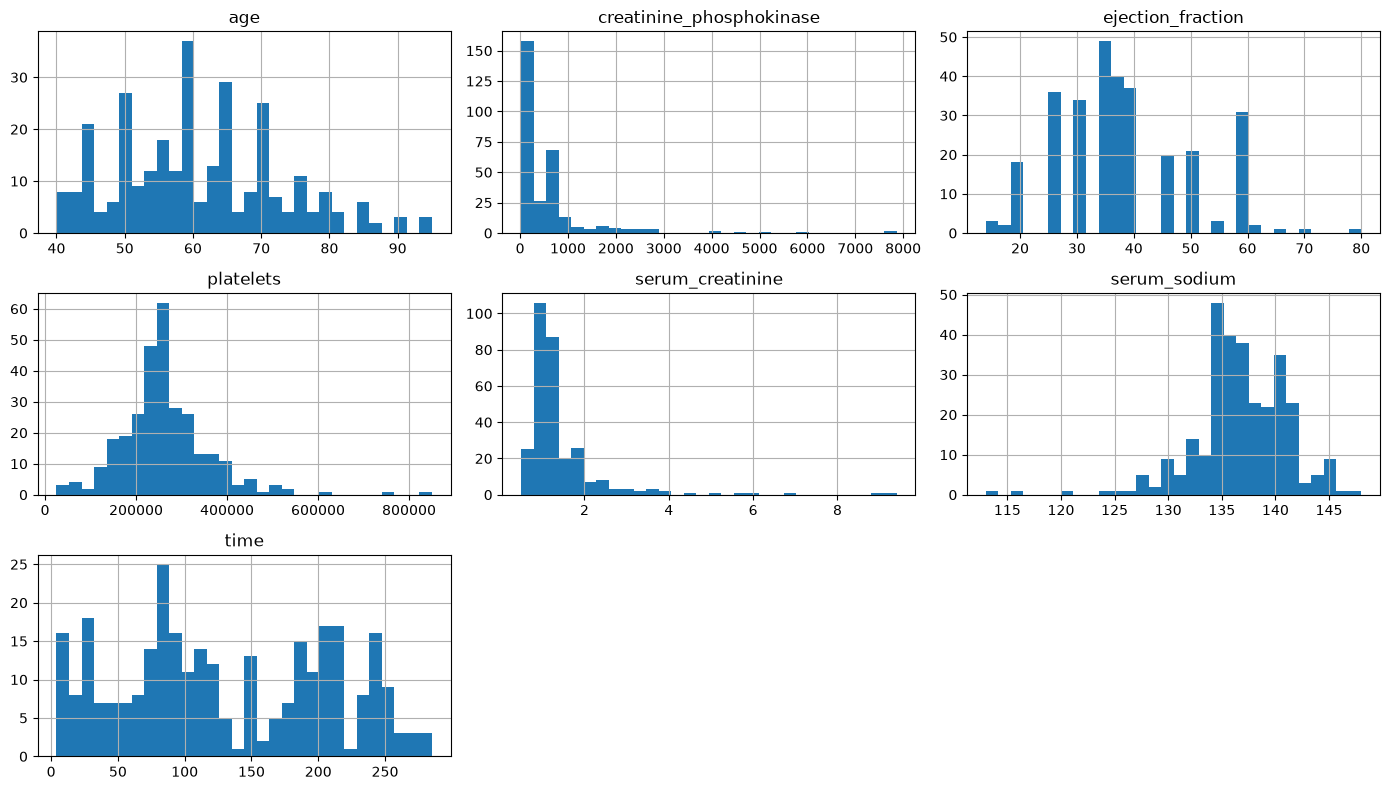

Skewness: {'age': 0.42, 'creatinine_phosphokinase': 4.46, 'ejection_fraction': 0.56, 'platelets': 1.46, 'serum_creatinine': 4.46, 'serum_sodium': -1.05, 'time': 0.13}
creatinine_phosphokinase  most common: {582: 47, 129: 4, 66: 4} | mean: 581.84
platelets                 most common: {263358.03: 25, 237000.0: 4, 228000.0: 4} | mean: 263358.03
serum_creatinine          most common: {1.0: 50, 1.1: 32, 0.9: 32} | mean: 1.39
serum_sodium              most common: {136: 40, 137: 38, 140: 35} | mean: 136.63

Serum creatinine values with two decimals: {1.18: 11, 1.83: 8, 0.75: 1}
Mean serum creatinine by outcome: {0: 1.185, 1: 1.836}


DEATH_EVENT,0,1
serum_creatinine,,
1.18,11,0
1.83,0,8
other,192,88


DEATH_EVENT                     0  1
serum_creatinine serum_sodium       
1.18             137           10  0
                 142            1  0
1.83             134            0  7
                 135            0  1

Death rate when CPK = 582: 0.362
Death rate when platelets = 263358.03: 0.4


,count,mean,std,min,25%,50%,75%,max
DEATH_EVENT,,,,,,,,
0,203.0,158.3,67.7,12.0,95.0,172.0,213.0,285.0
1,96.0,70.9,62.4,4.0,25.5,44.5,102.2,241.0


(299, 14) | share of patients who died: 0.321
Missing values to impute: {'serum_sodium': 17, 'log_cpk': 47, 'log_serum_creatinine': 19, 'platelets_k': 25}


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.84,11.89,40.00,51.00,60.00,70.00,95.00
anaemia,299.0,0.43,0.50,0.00,0.00,0.00,1.00,1.00
diabetes,299.0,0.42,0.49,0.00,0.00,0.00,1.00,1.00
ejection_fraction,299.0,38.08,11.83,14.00,30.00,38.00,45.00,80.00
high_blood_pressure,299.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00
serum_sodium,282.0,136.68,4.52,113.00,134.00,137.00,140.00,148.00
sex,299.0,0.65,0.48,0.00,0.00,1.00,1.00,1.00
smoking,299.0,0.32,0.47,0.00,0.00,0.00,1.00,1.00
cpk_imputed,299.0,0.16,0.36,0.00,0.00,0.00,0.00,1.00
platelets_imputed,299.0,0.08,0.28,0.00,0.00,0.00,0.00,1.00


Train size: 239 | Test size: 60


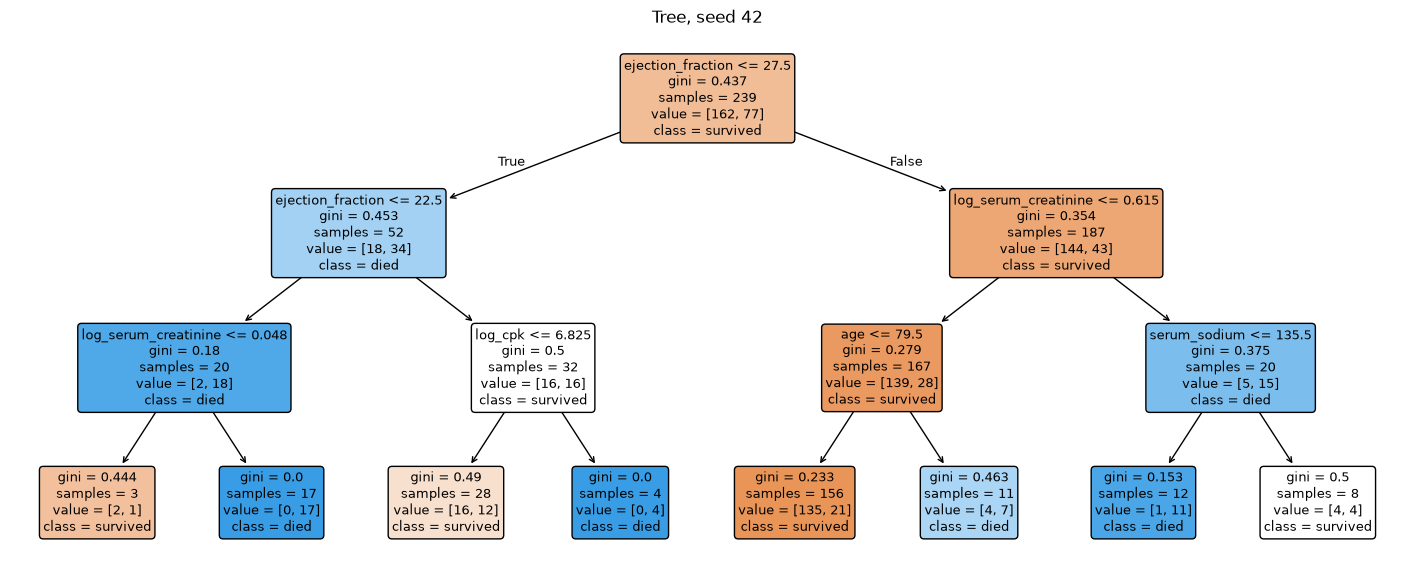

,coef,odds ratio,per SD
log_serum_creatinine,1.8796,6.5507,0.8754
ejection_fraction,-0.0663,0.9358,-0.7958
age,0.0408,1.0417,0.4670
high_blood_pressure,0.7067,2.0273,0.3424
anaemia,0.6479,1.9115,0.3228
diabetes,0.5437,1.7224,0.2709
log_cpk,0.2218,1.2483,0.2677
smoking,0.4446,1.5598,0.2075
creatinine_imputed,0.7265,2.0678,0.1710
sex,-0.2509,0.7781,-0.1207


Share of deaths in the test set: 0.317 -> accuracy of always predicting "survived": 0.683
Standard error of an accuracy near 0.75 with 60 test patients: about ±0.056


,accuracy,BCE,Brier
model,,,
Tree,0.817,0.522,0.166
Logistic,0.700,0.582,0.198


Tree


,Predicted survival (0),Predicted death (1)
Observed survival (0),39,2
Observed death (1),9,10


Logistic


,Predicted survival (0),Predicted death (1)
Observed survival (0),35,6
Observed death (1),12,7


accuracy             BCE           Brier       
model Logistic   Tree Logistic   Tree Logistic   Tree
seed                                                 
42       0.700  0.817    0.582  0.522    0.198  0.166
1        0.633  0.783    0.668  0.553    0.220  0.181
2        0.733  0.750    0.508  1.129    0.172  0.193
3        0.750  0.717    0.488  1.816    0.160  0.228
4        0.767  0.750    0.486  1.103    0.163  0.185

===== Tree, seed 42 =====
|--- ejection_fraction <= 27.50
|   |--- ejection_fraction <= 22.50
|   |   |--- log_serum_creatinine <= 0.05
|   |   |   |--- class: 0
|   |   |--- log_serum_creatinine >  0.05
|   |   |   |--- class: 1
|   |--- ejection_fraction >  22.50
|   |   |--- log_cpk <= 6.82
|   |   |   |--- class: 0
|   |   |--- log_cpk >  6.82
|   |   |   |--- class: 1
|--- ejection_fraction >  27.50
|   |--- log_serum_creatinine <= 0.61
|   |   |--- age <= 79.50
|   |   |   |--- class: 0
|   |   |--- age >  79.50
|   |   |   |--- class: 1
|   |--- log_serum_creatinine >  0.61
|   |   |--- serum_sodium <= 135.50
|   |   |   |--- class: 1
|   |   |--- serum_sodium >  135.50
|   |   |   |--- class: 0

===== Tree, seed 1 =====
|--- ejection_fraction <= 27.50
|   |--- ejection_fraction <= 22.50
|   |   |--- log_serum_creatinine <= 0.05
|   |   |   |--- class: 0
|   |   |--- log_serum_creatinine >  0.05
|   |   |   |--- class: 1
|   |--- ejection_fraction >  22.50
|   |   |--- log_cpk <

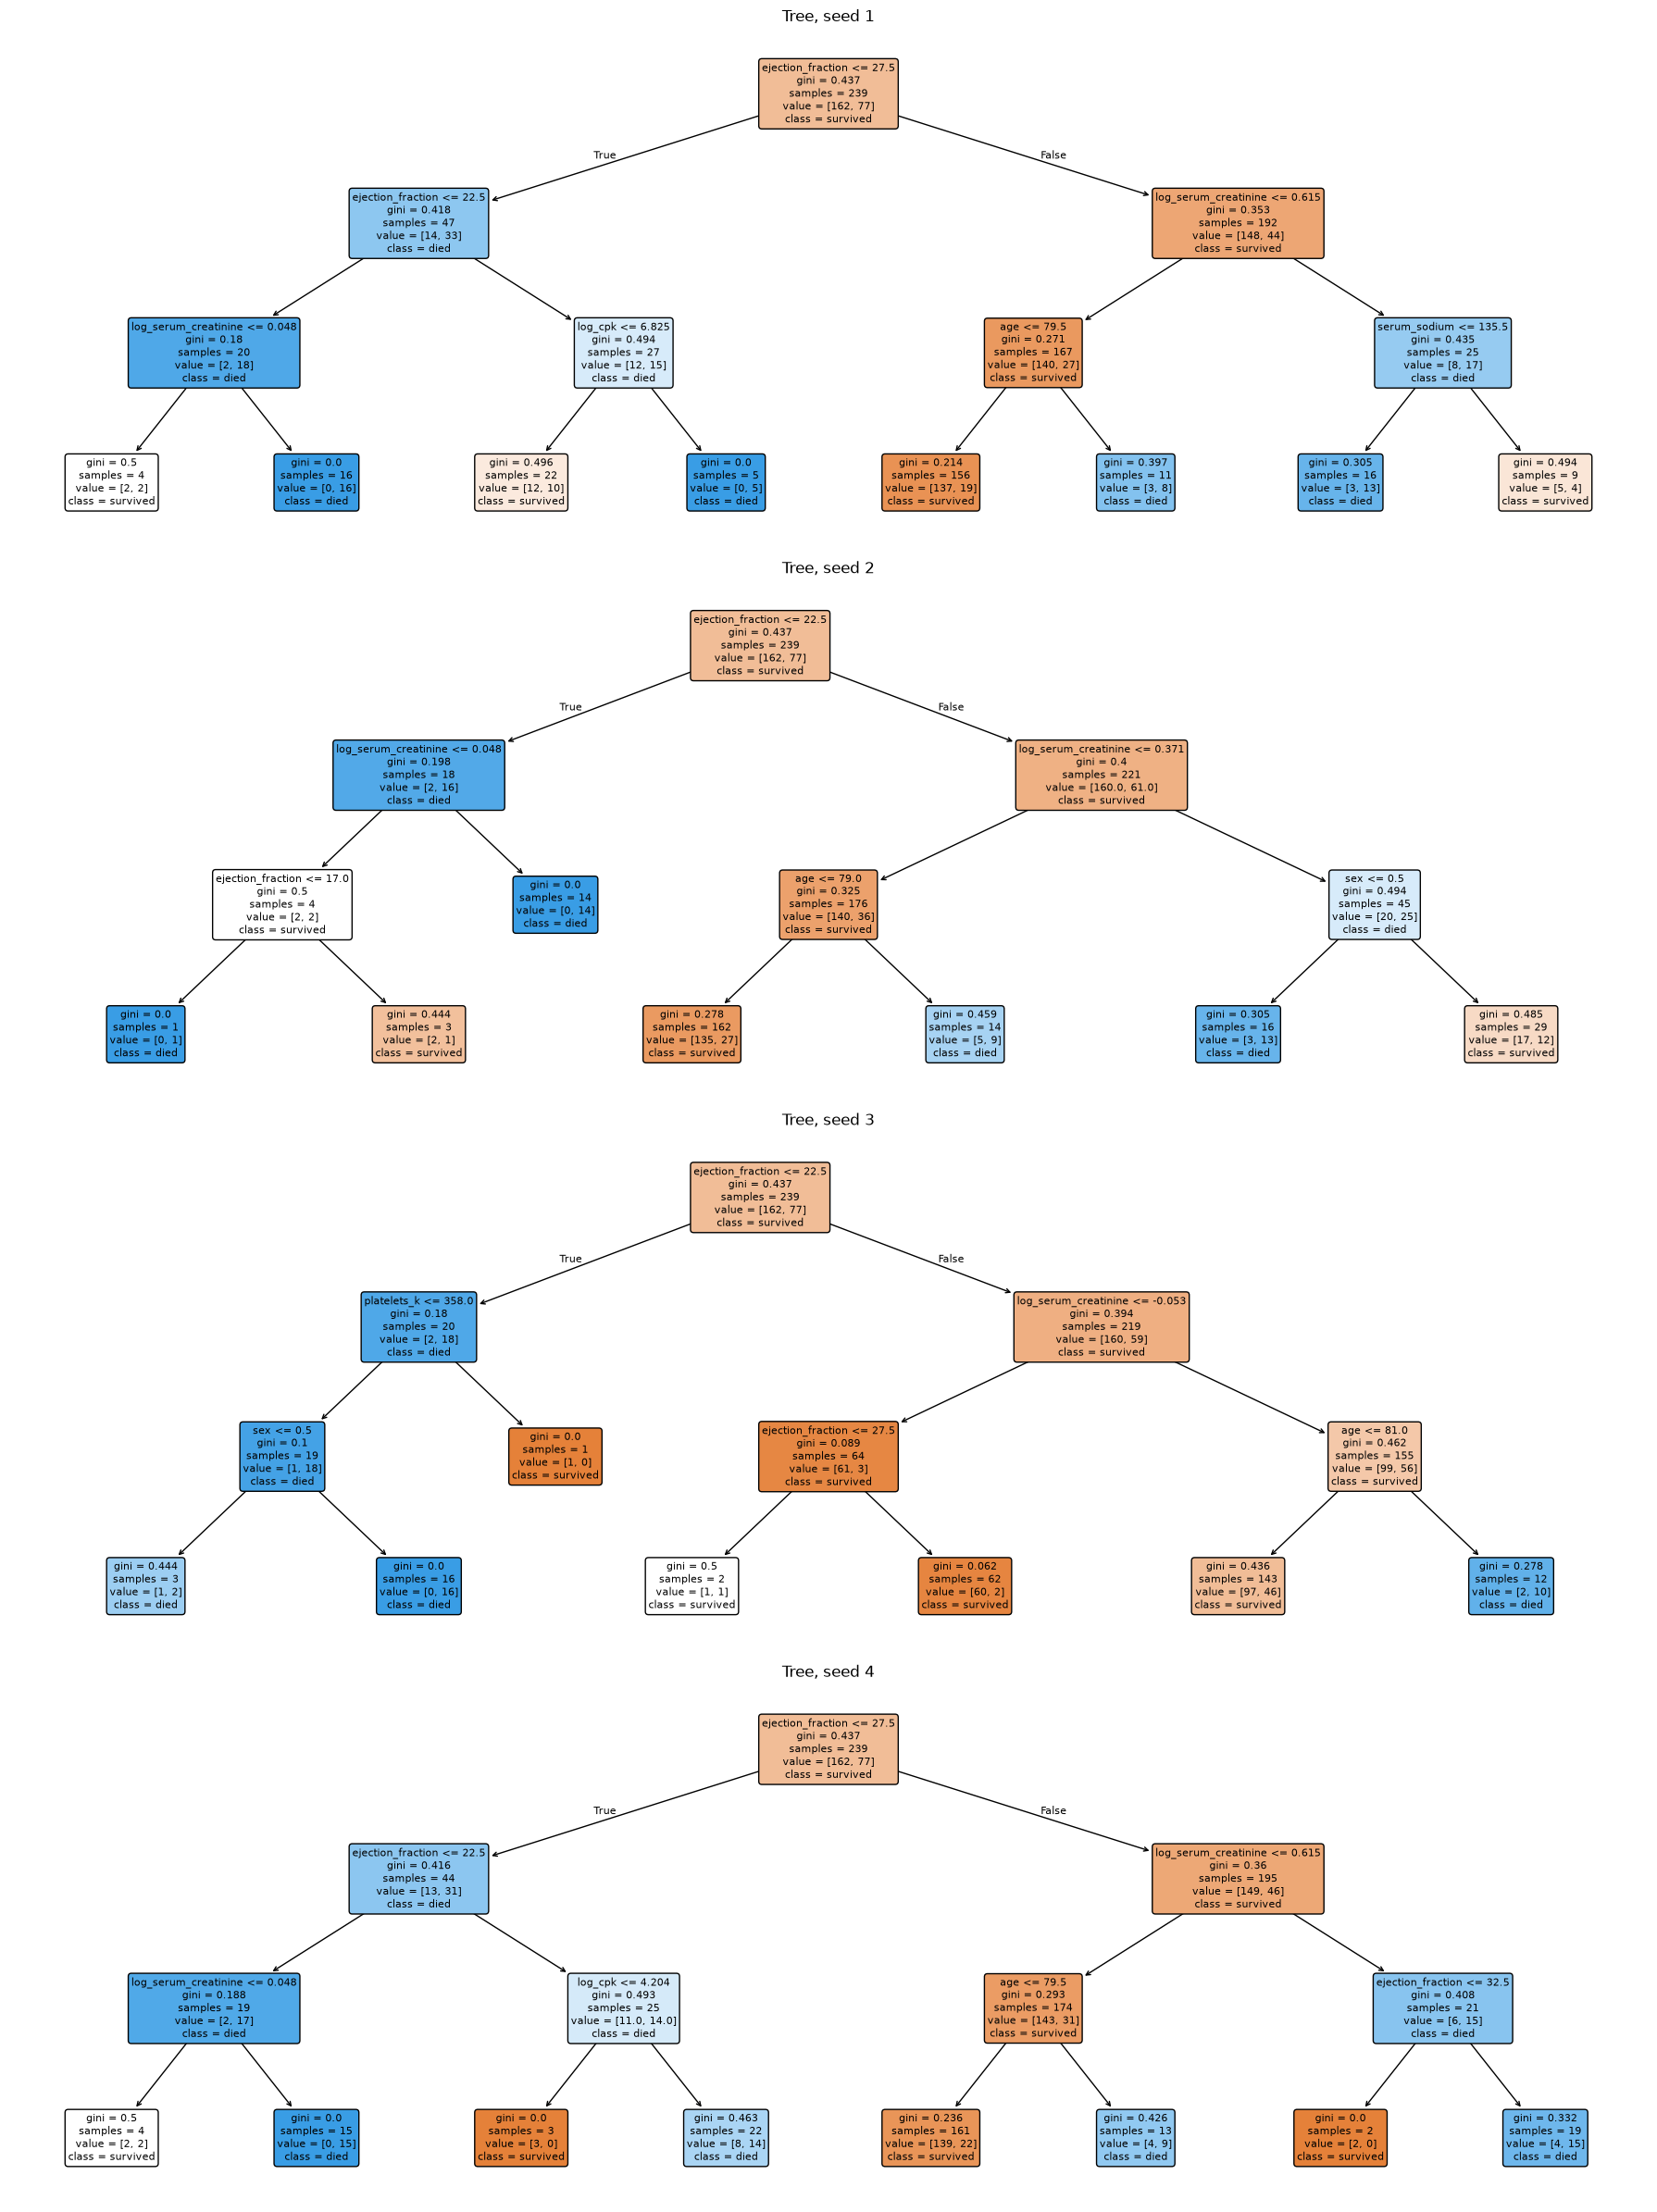

,seed 42,seed 1,seed 2,seed 3,seed 4
0,ejection_fraction <= 27.50,ejection_fraction <= 27.50,ejection_fraction <= 22.50,ejection_fraction <= 22.50,ejection_fraction <= 27.50
1,ejection_fraction <= 22.50,ejection_fraction <= 22.50,log_serum_creatinine <= 0.05,platelets_k <= 358.00,ejection_fraction <= 22.50
2,log_serum_creatinine <= 0.05,log_serum_creatinine <= 0.05,ejection_fraction <= 17.00,sex <= 0.50,log_serum_creatinine <= 0.05
3,log_cpk <= 6.82,log_cpk <= 6.82,log_serum_creatinine <= 0.37,log_serum_creatinine <= -0.05,log_cpk <= 4.20
4,log_serum_creatinine <= 0.61,log_serum_creatinine <= 0.61,age <= 79.00,ejection_fraction <= 27.50,log_serum_creatinine <= 0.61
5,age <= 79.50,age <= 79.50,sex <= 0.50,age <= 81.00,age <= 79.50
6,serum_sodium <= 135.50,serum_sodium <= 135.50,,,ejection_fraction <= 32.50


42     1
1      1
2     11
3      3
4      1
Name: distinct trees over 30 tree seeds, dtype: int64

,seed 42,seed 1,seed 2,seed 3,seed 4,mean,std,std / |mean|,same sign?
age,0.0408,0.0512,0.0472,0.0499,0.0436,0.0465,0.0043,0.0934,True
anaemia,0.6479,0.5491,0.3101,0.5536,0.4475,0.5016,0.1284,0.2560,True
diabetes,0.5437,-0.2537,0.1627,0.0777,0.3081,0.1677,0.2944,1.7557,False
ejection_fraction,-0.0663,-0.0839,-0.0692,-0.0580,-0.0681,-0.0691,0.0094,0.1359,True
high_blood_pressure,0.7067,0.1502,0.3375,0.1710,0.4320,0.3595,0.2268,0.6308,True
serum_sodium,-0.0136,-0.0219,-0.0590,-0.0627,-0.0218,-0.0358,0.0232,0.6477,True
sex,-0.2509,-0.7861,-0.4124,-0.3384,-0.5260,-0.4627,0.2070,0.4474,True
smoking,0.4446,0.0233,0.1220,0.1786,0.1096,0.1756,0.1603,0.9128,True
cpk_imputed,0.2356,0.3998,0.5678,0.1161,0.5707,0.3780,0.2015,0.5332,True
platelets_imputed,-0.0088,0.8610,0.5594,0.5676,0.6200,0.5199,0.3200,0.6156,False


,cpk_imputed,platelets_imputed,creatinine_imputed
cpk_imputed,1.00,0.30,0.34
platelets_imputed,0.30,1.00,0.66
creatinine_imputed,0.34,0.66,1.00


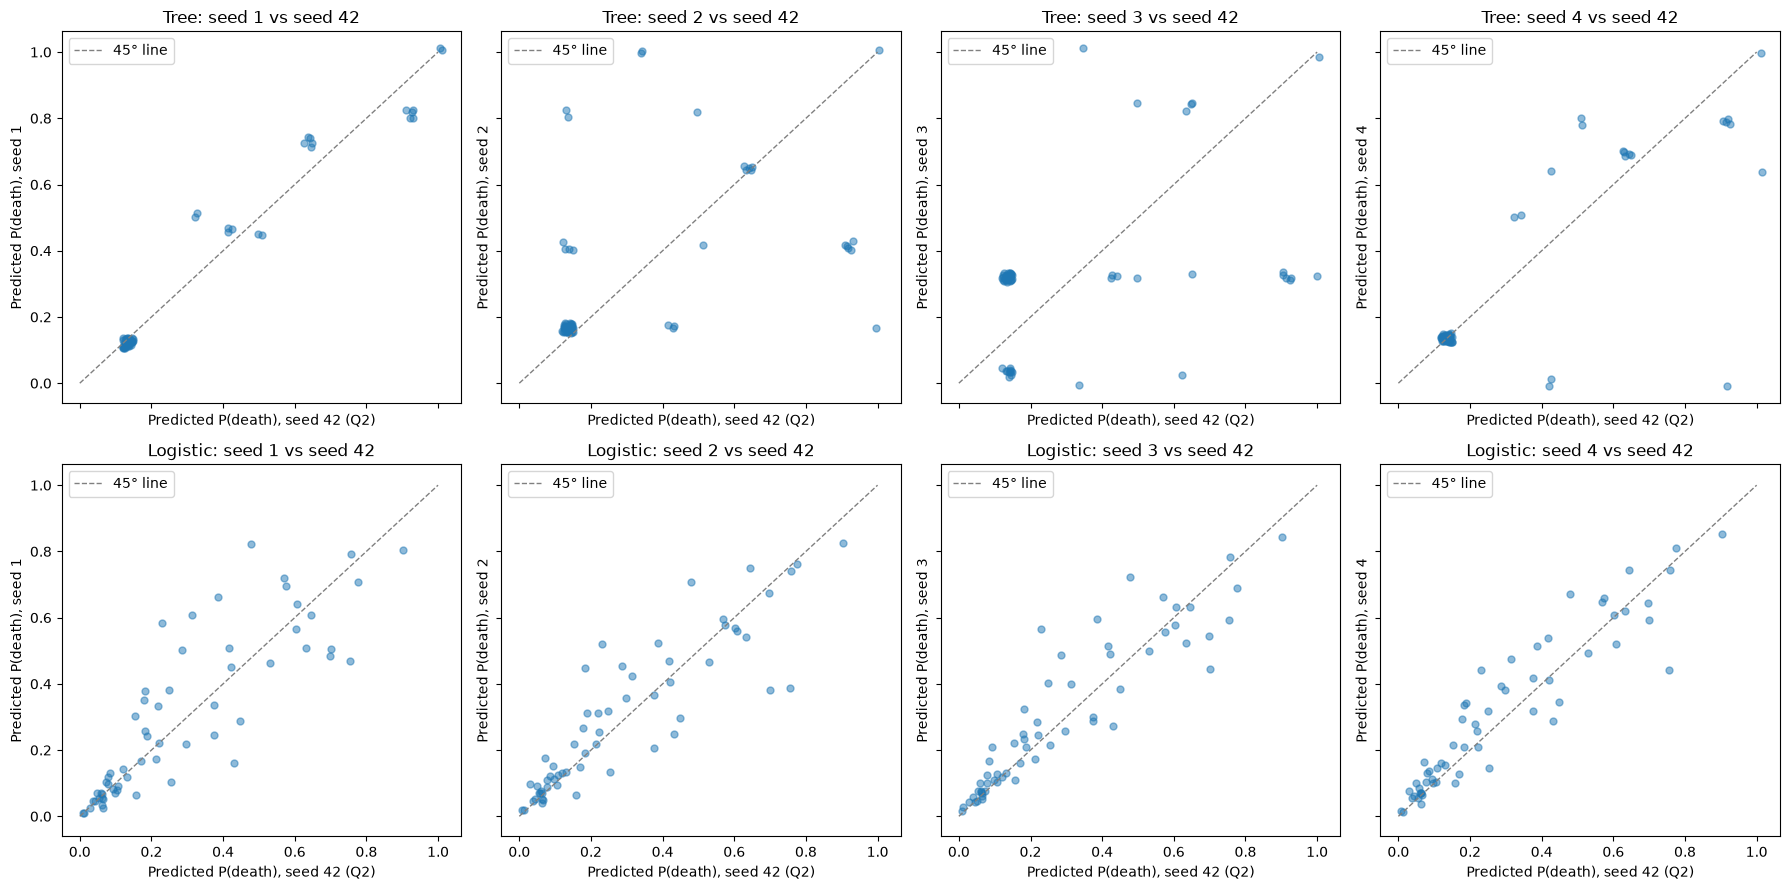

,Tree,Logistic
alternative seed,,
1,0.982,0.859
2,0.475,0.891
3,0.404,0.917
4,0.817,0.936
mean,0.670,0.901


,Tree,Logistic,Ridge logistic
mean,0.688,0.913,0.917
min,0.404,0.821,0.829
25%,0.606,0.895,0.900
50%,0.706,0.913,0.917
75%,0.778,0.939,0.941
max,0.982,0.974,0.974
share >= 0.8,0.200,1.000,1.000


intercept  slope    R^2  SD ratio (alt / Q2)
model    alt seed                                              
Tree     1             0.000  0.983  0.965                1.000
         2             0.194  0.418  0.226                0.880
         3             0.216  0.327  0.163                0.809
         4             0.046  0.786  0.667                0.962
Logistic 1             0.049  0.875  0.738                1.019
         2             0.056  0.836  0.794                0.938
         3             0.053  0.870  0.841                0.949
         4             0.050  0.904  0.876                0.966

,intercept,slope,R^2,SD ratio (alt / Q2)
model,,,,
Logistic,0.052,0.871,0.812,0.968
Tree,0.114,0.629,0.505,0.913


,training patients shared with seed 42,Q2 test patients in this training set
1,193,46
2,196,43
3,191,48
4,197,42


In [15]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss, confusion_matrix

pd.set_option('display.width', 200)
print('numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

DATA_PATH = './data/heart_failure/heart_failure_clinical_records_dataset.csv'
BASE_SEED = 42             # train-test split seed for Q2
ALT_SEEDS = [1, 2, 3, 4]   # train-test split seeds for Q3
TREE_SEED = 0              # fixed, so only the train-test split changes between models
TEST_SIZE = 0.2
MAX_DEPTH = 3              # small enough to read

# ==============================================================================================
# Q1. Explore and clean the data

df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())

# Data types, missing values, duplicate rows, and values of the binary variables
print(df.dtypes, '\n')
print('Missing values in total:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
binary_vars = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']
print({v: sorted(df[v].unique().tolist()) for v in binary_vars})

display(df.describe().T.round(2))

numeric_vars = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets',
                'serum_creatinine', 'serum_sodium', 'time']
df[numeric_vars].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()
print('Skewness:', df[numeric_vars].skew().round(2).to_dict())

# Hidden imputation 1: values repeated far more often than their neighbours
for var in ['creatinine_phosphokinase', 'platelets', 'serum_creatinine', 'serum_sodium']:
    print(f'{var:25s} most common: {df[var].value_counts().head(3).to_dict()} | mean: {df[var].mean():.2f}')

# Serum creatinine is recorded to one decimal place, except for three values
two_dec = df['serum_creatinine'][(df['serum_creatinine'] * 10).round(6) % 1 != 0]
print('\nSerum creatinine values with two decimals:', two_dec.value_counts().to_dict())

# Hidden imputation 2: the two-decimal creatinine values match the outcome-group means
print('Mean serum creatinine by outcome:', df.groupby('DEATH_EVENT')['serum_creatinine'].mean().round(3).to_dict())
sc_code = df['serum_creatinine'].where(df['serum_creatinine'].isin([1.18, 1.83]), 'other')
display(pd.crosstab(sc_code, df['DEATH_EVENT']))

# Serum sodium in the same 19 rows follows the same pattern
rows_sc = df['serum_creatinine'].isin([1.18, 1.83])
display(pd.crosstab([df.loc[rows_sc, 'serum_creatinine'], df.loc[rows_sc, 'serum_sodium']],
                    df.loc[rows_sc, 'DEATH_EVENT']))

# The CPK and platelet placeholders do NOT depend on the outcome (death rates close to the overall 0.32)
print('Death rate when CPK = 582:', round(df.loc[df['creatinine_phosphokinase'] == 582, 'DEATH_EVENT'].mean(), 3))
print('Death rate when platelets = 263358.03:',
      round(df.loc[np.isclose(df['platelets'], 263358.03), 'DEATH_EVENT'].mean(), 3))

# `time` is the follow-up period. It ends early when a patient dies.
display(df.groupby('DEATH_EVENT')['time'].describe().round(1))

# What the exploration shows
#
# - 299 patients, 13 numeric columns, no missing values, no duplicate rows. The binary variables
#   only take the values 0 and 1, and the ranges are clinically plausible (age 40-95, ejection
#   fraction 14-80%, sodium 113-148 mEq/L).
# - Hidden mean imputation: CPK = 582 appears 47 times and platelets = 263358.03 appears 25
#   times, both equal to the column mean. These were missing values filled with the overall
#   mean. They don't depend on the outcome (death rates 0.36 and 0.40, vs. 0.32 overall).
# - Hidden imputation that leaks the outcome: creatinine is recorded to one decimal, except for
#   1.18 (11 patients, all survivors), 1.83 (8 patients, all deaths) and one 0.75. 1.18 and 1.83
#   are the survivor and death means (1.185 and 1.836), so these values were filled in using the
#   outcome. In the same rows, sodium is 137 for 10 of the 11 survivors and 134 for 7 of the 8
#   deaths. Kept as they are, these values let a model read the answer: they must not be used.
# - CPK and creatinine are strongly right-skewed (skewness 4.46 each). Platelets are on a scale
#   of hundreds of thousands.
# - `time` leaks the outcome: it is the follow-up period, which ends when a patient dies (mean
#   71 days for deaths vs. 158 for survivors). It isn't known when predicting for a new patient.
#
# Cleaning decisions
#
# | Step | Why |
# | Drop `time` | Outcome leakage (see above). |
# | Flag the placeholders (`cpk_imputed`, `platelets_imputed`, `creatinine_imputed`), set them to missing | The flags keep the information that a value was missing (missingness can be informative) without the fake value. The flags themselves do not encode the outcome (42% deaths among flagged creatinine rows). |
# | Median-impute inside each training split (`SimpleImputer` in a pipeline) | The test set never informs the imputation. The median is robust to the skew. |
# | Log-transform CPK and creatinine | Stops a few extreme values from dominating the logistic regression. Trees are unaffected, since a monotone transform keeps the same orderings and therefore the same possible splits. |
# | Platelets in thousands; round the two ages of 60.667 | Readability only. Neither changes any conclusion. |

df_clean = df.copy()

# 1. Flag the hidden imputations
cpk_imp = df_clean['creatinine_phosphokinase'] == 582
plt_imp = np.isclose(df_clean['platelets'], 263358.03)
sc_imp = df_clean['serum_creatinine'].isin([1.18, 1.83])
na_imp = sc_imp & df_clean['serum_sodium'].isin([134, 137])   # sodium imputed in the same rows
df_clean['cpk_imputed'] = cpk_imp.astype(int)
df_clean['platelets_imputed'] = plt_imp.astype(int)
df_clean['creatinine_imputed'] = sc_imp.astype(int)

# 2. Set the imputed values back to missing. They are re-imputed inside each training split (see fit_models).
df_clean.loc[cpk_imp, 'creatinine_phosphokinase'] = np.nan
df_clean.loc[plt_imp, 'platelets'] = np.nan
df_clean.loc[sc_imp, 'serum_creatinine'] = np.nan
df_clean.loc[na_imp, 'serum_sodium'] = np.nan

# 3. Log-transform the right-skewed lab values, rescale platelets, round the two ages of 60.667
df_clean['log_cpk'] = np.log(df_clean['creatinine_phosphokinase'])
df_clean['log_serum_creatinine'] = np.log(df_clean['serum_creatinine'])
df_clean['platelets_k'] = df_clean['platelets'] / 1000
df_clean['age'] = df_clean['age'].round()

# 4. Drop the raw versions and `time` (outcome leakage)
df_clean = df_clean.drop(columns=['creatinine_phosphokinase', 'serum_creatinine', 'platelets', 'time'])

y = df_clean['DEATH_EVENT']
X = df_clean.drop(columns='DEATH_EVENT')
print(X.shape, '| share of patients who died:', round(y.mean(), 3))
print('Missing values to impute:', X.isna().sum()[X.isna().sum() > 0].to_dict())
display(X.describe().T.round(2))

# ==============================================================================================
# Q2. Train-test split, tree and logistic regression (seed 42)
#
# 80/20 split, stratified on `DEATH_EVENT`. Each model is a pipeline: median imputation (fit on
# the training set only), then the model. The logistic regression is unpenalized (`C=np.inf`),
# so its coefficients are ordinary maximum-likelihood estimates.

def fit_models(seed):
    """Split with `seed`; fit an imputer + tree and an imputer + logistic regression on the training set."""
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=seed, stratify=y)
    tree = make_pipeline(SimpleImputer(strategy='median'),
                         DecisionTreeClassifier(max_depth=MAX_DEPTH, random_state=TREE_SEED))
    lm = make_pipeline(SimpleImputer(strategy='median'),
                       LogisticRegression(C=np.inf, max_iter=10_000, tol=1e-8))
    return tree.fit(X_train, y_train), lm.fit(X_train, y_train), X_train, X_test, y_train, y_test

def evaluate(models, X_test, y_test):
    """Accuracy (threshold 0.5), BCE / log loss and Brier score of the predicted probabilities."""
    rows = []
    for name, m in models.items():
        p = m.predict_proba(X_test)[:, 1]
        rows.append({'model': name, 'accuracy': accuracy_score(y_test, m.predict(X_test)),
                     'BCE': log_loss(y_test, p), 'Brier': brier_score_loss(y_test, p)})
    return pd.DataFrame(rows).set_index('model').round(3)

tree_base, lm_base, X_train_base, X_test_base, y_train_base, y_test_base = fit_models(BASE_SEED)
print('Train size:', len(X_train_base), '| Test size:', len(X_test_base))

plt.figure(figsize=(18, 7))
plot_tree(tree_base[-1], feature_names=list(X.columns), class_names=['survived', 'died'],
          filled=True, rounded=True, fontsize=9)
plt.title(f'Tree, seed {BASE_SEED}')
plt.show()

# Coefficients on the log-odds scale. `per SD` = coefficient x training-set SD, so sizes can be compared.
coef_base = pd.DataFrame({'coef': lm_base[-1].coef_[0]}, index=X.columns)
coef_base['odds ratio'] = np.exp(coef_base['coef'])
coef_base['per SD'] = coef_base['coef'] * X_train_base.std()
display(coef_base.round(4).sort_values('per SD', key=abs, ascending=False))

print('Share of deaths in the test set:', round(y_test_base.mean(), 3),
      '-> accuracy of always predicting "survived":', round(1 - y_test_base.mean(), 3))
se = np.sqrt(0.75 * 0.25 / len(y_test_base))
print(f'Standard error of an accuracy near 0.75 with {len(y_test_base)} test patients: about ±{se:.3f}')
display(evaluate({'Tree': tree_base, 'Logistic': lm_base}, X_test_base, y_test_base))

# Confusion matrices on the test set (rows = observed, columns = predicted)
for name, m in [('Tree', tree_base), ('Logistic', lm_base)]:
    cm = pd.DataFrame(confusion_matrix(y_test_base, m.predict(X_test_base)),
                      index=['Observed survival (0)', 'Observed death (1)'],
                      columns=['Predicted survival (0)', 'Predicted death (1)'])
    print(name); display(cm)

# Set aside the Q2 predictions (probability of death) on the Q2 test set
pred_tree_base = tree_base.predict_proba(X_test_base)[:, 1]
pred_lm_base = lm_base.predict_proba(X_test_base)[:, 1]

# Tree (seed 42). The root splits on `ejection_fraction <= 27.5`. Patients with low ejection
# fraction are split further on ejection fraction (≤ 22.5), creatinine (≈ 1.05 mg/dL) and CPK (≈
# 920). Patients with higher ejection fraction are split on creatinine (≈ 1.85 mg/dL), then on
# age (79.5) and sodium (135.5).
#
# Logistic regression (log-odds scale). Per standard deviation, the largest effects are
# creatinine (+0.88), ejection fraction (-0.80) and age (+0.47). Doubling creatinine multiplies
# the odds of death by 2^1.88 ≈ 3.7. Each extra ejection-fraction point multiplies them by
# e^-0.066 ≈ 0.94, and each year of age by e^0.041 ≈ 1.04.
#
# Test-set performance (baseline "always survived" = 68.3%):
#
# | | Accuracy | BCE | Brier |
# | Tree | 81.7% | 0.522 | 0.166 |
# | Logistic | 70.0% | 0.582 | 0.198 |
#
# Both models beat the baseline, the tree by more on this split. At threshold 0.5 both miss many
# deaths: the tree misses 9 of the 19, the logistic regression 12. With only 60 test patients,
# an accuracy near 75% has a standard error of about ±5.6 points, so a gap from one split is not
# evidence that one model is better. The predicted probabilities are saved as `pred_tree_base`
# and `pred_lm_base`.

# ==============================================================================================
# Q3. Repeating the analysis with four more seeds
#
# Each model is trained and evaluated on its own split. For Q4, every model also predicts on the
# Q2 test set (`X_test_base`), so all predictions are for the same 60 patients.

alt_trees, alt_lms, pred_tree_alt, pred_lm_alt = {}, {}, {}, {}
perf = [evaluate({'Tree': tree_base, 'Logistic': lm_base}, X_test_base, y_test_base).assign(seed=BASE_SEED)]

for s in ALT_SEEDS:
    tree_s, lm_s, X_tr, X_te, y_tr, y_te = fit_models(s)
    alt_trees[s], alt_lms[s] = tree_s, lm_s
    perf.append(evaluate({'Tree': tree_s, 'Logistic': lm_s}, X_te, y_te).assign(seed=s))  # own test set
    pred_tree_alt[s] = tree_s.predict_proba(X_test_base)[:, 1]   # Q2 test set, for Q4
    pred_lm_alt[s] = lm_s.predict_proba(X_test_base)[:, 1]

all_trees = {BASE_SEED: tree_base, **alt_trees}
all_lms = {BASE_SEED: lm_base, **alt_lms}
perf_df = pd.concat(perf).reset_index().pivot(index='seed', columns='model').reindex(all_trees)
display(perf_df)

for s, t in all_trees.items():
    print(f'===== Tree, seed {s} =====')
    print(export_text(t[-1], feature_names=list(X.columns), decimals=2))

fig, axes = plt.subplots(len(ALT_SEEDS), 1, figsize=(18, 6 * len(ALT_SEEDS)))
for ax, (s, t) in zip(axes, alt_trees.items()):
    plot_tree(t[-1], feature_names=list(X.columns), class_names=['survived', 'died'],
              filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f'Tree, seed {s}')
plt.tight_layout()
plt.show()

# Every split of every tree, in node order (node 0 = root)
def splits(t):
    tr = t[-1].tree_
    return [f'{X.columns[f]} <= {th:.2f}' for f, th in zip(tr.feature, tr.threshold) if f >= 0]

display(pd.DataFrame({f'seed {s}': pd.Series(splits(t)) for s, t in all_trees.items()}).fillna(''))

# Is each tree determined by its training data alone? Refit every split with 30 different tree seeds.
# A tree seed only matters when two candidate splits are exactly tied.
def n_distinct_trees(seed, n=30):
    X_tr, _, y_tr, _ = train_test_split(X, y, test_size=TEST_SIZE, random_state=seed, stratify=y)
    X_tr = SimpleImputer(strategy='median').fit_transform(X_tr)
    fits = [DecisionTreeClassifier(max_depth=MAX_DEPTH, random_state=r).fit(X_tr, y_tr) for r in range(n)]
    return len({tuple(zip(f.tree_.feature, f.tree_.threshold.round(6))) for f in fits})

display(pd.Series({s: n_distinct_trees(s) for s in all_trees}, name='distinct trees over 30 tree seeds'))

seed_cols = [f'seed {s}' for s in all_lms]
coefs = pd.DataFrame({f'seed {s}': m[-1].coef_[0] for s, m in all_lms.items()}, index=X.columns)
coefs['mean'] = coefs[seed_cols].mean(axis=1)
coefs['std'] = coefs[seed_cols].std(axis=1)
coefs['std / |mean|'] = coefs['std'] / coefs['mean'].abs()
coefs['same sign?'] = np.sign(coefs[seed_cols]).nunique(axis=1) == 1
display(coefs.round(4))

# Correlations among the imputation flags (used in the explanation below)
display(X[['cpk_imputed', 'platelets_imputed', 'creatinine_imputed']].corr().round(2))

# How different are the trees? It depends on the seed.
# - Seeds 42 and 1 give identical splits. The two training sets share 193 of 239 patients.
# - Seed 4 has the same root and first-level splits, but a different CPK threshold (4.20 vs.
#   6.82) and a final split on ejection fraction instead of sodium.
# - Seeds 2 and 3 are different trees. Their root is `ejection_fraction <= 22.5`, and below it
#   they split on sex (seeds 2 and 3) and platelets (seed 3), which the seed-42 tree never uses.
# - Part of this is not caused by the data at all. Refitting the same training set with 30
#   different tree seeds gives 11 different trees for split 2 and 3 for split 3, because some
#   candidate splits are exactly tied. Trees are unstable to small changes in the data, and on a
#   small dataset even to arbitrary tie-breaking. That is why `TREE_SEED` is fixed.
# - Seed 3 contains splits whose two leaves predict the same class (e.g. `sex`). They change the
#   predicted probabilities but not the predicted class.
#
# How different are the logistic regression coefficients? Much less for the strong predictors.
# Creatinine ranges from 1.29 to 1.88, ejection fraction from -0.058 to -0.084 and age from
# 0.041 to 0.051. All three keep the same sign, with std / |mean| between 0.09 and 0.16. Weak
# predictors move a lot: smoking ranges from 0.02 to 0.44 and high blood pressure from 0.15 to
# 0.71. Diabetes, `platelets_k`, `platelets_imputed` and `creatinine_imputed` even change sign.
#
# Performance by seed (each on its own test set). Tree accuracy is 0.72-0.82 and logistic
# accuracy 0.63-0.77. The tree's BCE jumps from 0.52 to 1.82 because pure leaves predict exactly
# 0 or 1, so one confident mistake costs a lot. On the Brier score, which has no such blow-up,
# the two models are close (tree 0.17-0.23, logistic 0.16-0.22).

# ==============================================================================================
# Q4. Comparing predictions across seeds (all on the Q2 test set)
#
# Why do the logistic regression coefficients vary by different amounts?
#
# A predictor with a strong, consistent effect is estimated well from any 80% sample. A
# predictor whose true effect is near zero is estimated mostly from noise, so swapping a few
# patients moves it a lot relative to its size, sometimes past zero. Collinearity makes it
# worse: `platelets_imputed` and `creatinine_imputed` are correlated (0.66, mostly the same
# patients), so the model can shift weight between them from one split to the next. Their
# coefficients swing the most (-0.01 to 0.86 and -0.18 to 0.73). Rare binary groups (6-16%
# flagged) and only 77 deaths per training set add noise, and the unpenalized fit (`C=np.inf`)
# does nothing to shrink it.

# ==============================================================================================
# 4a. Scatterplots
# Tree predictions take only a few distinct values, so many patients sit on the same point. I
# add a small horizontal and vertical jitter (±0.015) to the tree plots so stacked points are
# visible. The correlations and regressions below use the unjittered values.

rng = np.random.default_rng(0)   # jitter only, does not affect any result
fig, axes = plt.subplots(2, len(ALT_SEEDS), figsize=(4.5 * len(ALT_SEEDS), 9), sharex=True, sharey=True)
rows = [('Tree', pred_tree_base, pred_tree_alt, 0.015), ('Logistic', pred_lm_base, pred_lm_alt, 0.0)]
for r, (name, base, alt, jit) in enumerate(rows):
    for c, s in enumerate(ALT_SEEDS):
        ax = axes[r, c]
        ax.scatter(base + rng.uniform(-jit, jit, base.size), alt[s] + rng.uniform(-jit, jit, base.size),
                   alpha=0.5, s=25)
        ax.plot([0, 1], [0, 1], color='gray', ls='--', lw=1, label='45° line')
        ax.set_title(f'{name}: seed {s} vs seed {BASE_SEED}')
        ax.set_xlabel(f'Predicted P(death), seed {BASE_SEED} (Q2)')
        ax.set_ylabel(f'Predicted P(death), seed {s}')
        ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Logistic regression: similar. In all four panels the points follow the 45° line in a
# moderately tight band, so patients the seed-42 model rates as high-risk are rated high-risk by
# the others. The band is widest for seed 1.
#
# Trees: it depends on the seed. Seed 1 sits on the 45° line (same splits, slightly different
# leaf proportions). Seed 4 is mostly on the line, with a few patients moved to very different
# leaves (e.g. 0.6 or 0.9 → 0). Seeds 2 and 3 show little relationship. Seed 3 gives most
# patients about 0.03 or 0.32, including most of the patients the seed-42 tree rates at about
# 0.9. Seed 2 rates some of the seed-42 low-risk patients (0.13) at about 0.8, and most of its
# 0.9 group at about 0.4.

# ==============================================================================================
# 4b. Correlations with the Q2 predictions

corr = pd.DataFrame({
    'Tree': {s: np.corrcoef(pred_tree_base, pred_tree_alt[s])[0, 1] for s in ALT_SEEDS},
    'Logistic': {s: np.corrcoef(pred_lm_base, pred_lm_alt[s])[0, 1] for s in ALT_SEEDS},
})
corr.index.name = 'alternative seed'
corr.loc['mean'] = corr.mean()
display(corr.round(3))

# Logistic regression: highly correlated: 0.86, 0.89, 0.92 and 0.94 (mean 0.90).
#
# Trees: not consistently. Seed 1 is 0.98 and seed 4 is 0.82, but seeds 2 and 3 are only 0.48
# and 0.40. The mean (0.67) is lower than for logistic regression, and the spread across seeds
# is much larger (0.40-0.98 vs. 0.86-0.94). The best tree pair beats every logistic pair only
# because those two trees are identical.

# Robustness: repeat the 4b comparison for 100 alternative seeds (takes about 10-20 seconds).
# Also fit a ridge-penalized logistic regression (standardized features, C=1) on each split, for the Q5 caveat.
def fit_ridge(X_tr, y_tr):
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                         LogisticRegression(C=1.0, max_iter=10_000)).fit(X_tr, y_tr)

pred_ridge_base = fit_ridge(X_train_base, y_train_base).predict_proba(X_test_base)[:, 1]
MANY_SEEDS = [s for s in range(1, 102) if s != BASE_SEED][:100]
many_rows = []
for s in MANY_SEEDS:
    t, l, X_tr, _, y_tr, _ = fit_models(s)
    many_rows.append({
        'Tree': np.corrcoef(pred_tree_base, t.predict_proba(X_test_base)[:, 1])[0, 1],
        'Logistic': np.corrcoef(pred_lm_base, l.predict_proba(X_test_base)[:, 1])[0, 1],
        'Ridge logistic': np.corrcoef(pred_ridge_base, fit_ridge(X_tr, y_tr).predict_proba(X_test_base)[:, 1])[0, 1]})
many = pd.DataFrame(many_rows, index=MANY_SEEDS)
summary = many.describe().loc[['mean', 'min', '25%', '50%', '75%', 'max']]
summary.loc['share >= 0.8'] = (many >= 0.8).mean()
display(summary.round(3))

# Robustness (100 alternative seeds). The median correlation with the Q2 predictions is 0.71 for
# trees (middle half 0.61-0.78; only 20% reach 0.8) and 0.91 for logistic regression (middle
# half 0.90-0.94; all at least 0.82). The four seeds above are typical, not a quirk of the seeds
# I picked.

# ==============================================================================================
# 4c. Regression of the alternative predictions on the Q2 predictions
#
# For each alternative seed: `prediction_alt = intercept + slope × prediction_Q2`. In a simple
# regression, slope = correlation × (SD of alt predictions / SD of Q2 predictions), so I also
# show the SD ratio.

reg_rows = []
for name, base, alt in [('Tree', pred_tree_base, pred_tree_alt), ('Logistic', pred_lm_base, pred_lm_alt)]:
    for s in ALT_SEEDS:
        reg = LinearRegression().fit(base.reshape(-1, 1), alt[s])
        reg_rows.append({'model': name, 'alt seed': s, 'intercept': reg.intercept_, 'slope': reg.coef_[0],
                         'R^2': reg.score(base.reshape(-1, 1), alt[s]),
                         'SD ratio (alt / Q2)': alt[s].std() / base.std()})
reg_df = pd.DataFrame(reg_rows).set_index(['model', 'alt seed'])
display(reg_df.round(3))
display(reg_df.groupby('model').mean().round(3))

# Identical predictions would give intercept 0, slope 1 and R² 1.
#
# Logistic regression: close. Intercepts are 0.05-0.06 (small on a 0-1 scale), slopes 0.84-0.90
# and R² 0.74-0.88 (mean 0.81). The slopes are below 1 because the correlations are below 1
# (slope = correlation × SD ratio). The alternative predictions are about as spread out as the
# Q2 ones (SD ratio 0.94-1.02).
#
# Trees: mixed. Seed 1 is almost exactly (0, 1, 1): intercept 0.00, slope 0.98, R² 0.97. Seed 4
# is moderately close: 0.05, 0.79, 0.67. Seeds 2 and 3 are far off: intercepts 0.19 and 0.22,
# slopes 0.42 and 0.33, R² 0.23 and 0.16. On average the trees (0.11, 0.63, 0.51) are much
# further from (0, 1, 1) than the logistic regressions (0.05, 0.87, 0.81).

# How independent are these comparisons? Overlap between the splits.
train_base = set(X_train_base.index); test_base = set(X_test_base.index)
overlap = {}
for s in ALT_SEEDS:
    X_tr, _, _, _ = train_test_split(X, y, test_size=TEST_SIZE, random_state=s, stratify=y)
    overlap[s] = {'training patients shared with seed 42': len(train_base & set(X_tr.index)),
                  'Q2 test patients in this training set': len(test_base & set(X_tr.index))}
display(pd.DataFrame(overlap).T)

# ==============================================================================================
# Q5. Are the coefficients and predictions similar across splits?
#
# Logistic regression: yes. The coefficients that matter (creatinine, ejection fraction, age)
# are stable in size and sign. The ones that move belong to weak or collinear predictors. The
# predictions agree closely: correlations 0.86-0.94 (median 0.91 over 100 seeds), intercepts
# near 0, slopes 0.84-0.90 and R² 0.74-0.88. Logistic regression is a low-variance model.
#
# Trees: no. The structure changes from split to split. Seeds 2 and 3 have a different root
# threshold and different variables, and their structure also depends on tie-breaking. The
# predictions change with it: correlations of 0.40-0.48 and R² below 0.25 for those seeds. Only
# seed 1, with an identical tree, and to a lesser degree seed 4 predict similarly. Over 100
# seeds the median tree correlation is 0.71. Trees are high-variance models.
#
# Caveats:
# - The logistic regression is unpenalized, which leaves its weak coefficients as noisy as
#   possible. A ridge-penalized version (standardized features, C = 1) is slightly more stable
#   (median correlation 0.917 vs. 0.913 over 100 seeds), so the stability found for logistic
#   regression is, if anything, understated.
# - Each alternative training set shares 191-197 of its 239 patients with seed 42, so these
#   models are more alike than models trained on independent samples would be. 42-48 of the 60
#   comparison patients were also in each alternative training set, so some alternative
#   predictions are in-sample.
# - The trees have depth 3 and the dataset has 299 patients (96 deaths). Deeper trees would
#   probably vary even more.

# ==============================================================================================
# Q6. True or false
#
# "Even if the models end up having a substantially different appearance, the predictions they
# generate are often very similar."
#
# False for this dataset.
#
# The models whose appearance changes substantially here are the trees: their root, variables
# and thresholds change from split to split. When a tree looked substantially different, its
# predictions were substantially different too. Seeds 2 and 3 correlate only 0.48 and 0.40 with
# the Q2 tree (R² 0.23 and 0.16). The trees that predict similarly also look similar: seed 1 is
# identical (0.98) and seed 4 differs only in two lower splits (0.82). Over 100 seeds the median
# tree correlation is 0.71 and only 20% reach 0.8, so very similar predictions are not the
# typical outcome.
#
# Logistic regression is the contrast. Its predictions are very similar across splits
# (0.86-0.94; median 0.91 over 100 seeds), but its appearance does not change substantially
# either: the strong coefficients are stable and only weak ones move, some flipping sign. So it
# shows that weak coefficients can change without changing the predictions. It does not show
# that models that look substantially different predict alike. For the trees, which do look
# substantially different, the predictions diverge, which is why averaging many trees (bagging,
# random forests) helps.

### *Reflection on AI assistance
In your own words without generative AI.


The most important improvement was catching outcome leakage that Phase 1 missed. The creatinine values 1.18 and 1.83 turned out to be the survivor and death means, so the Phase 1 trees were partly reading the answer, and the seed-42 tree's root split sat right at the leaked value. Setting those values to missing and re-imputing inside each training split with a pipeline made the analysis much more honest. Other good changes were fixing the tree seed so that only the data split varies, adding the Brier score next to BCE, adding a 100-seed robustness check, and correcting interpretation errors such as the claim about the slope and the wrong collinearity claim.

The AI also made mistakes. It claimed several Phase 1 tables were never displayed, which was false. It suggested moving the coefficient explanation out of Q4, even though the rubric grades it there (4.1). Its follow-up said ridge raised the median correlation from 0.91 to 0.94, but the final output shows only 0.913 to 0.917. The Phase 1 AI also stated some explanations confidently that turned out to be wrong.

I verified the revision by re-running the notebook and checking the main claims against its outputs: the creatinine and sodium crosstabs, the overlap counts (191-197 and 42-48), the flag correlations, and every number quoted in the written answers.

Some concerns remain. The Q6 verdict ("False") is a judgment call that depends on how "substantially different" is read. With only 60 test patients, single-split results are noisy. Some tree differences come from tie-breaking rather than the data. Finally, putting everything in one code cell with comment text is harder to read than separate markdown cells.